In [5]:
import zipfile
import os

zip_path = "/content/archive (11).zip"
extract_path = "/content/malaria_dataset"

os.makedirs(extract_path, exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted successfully!")
print(os.listdir(extract_path))

Dataset extracted successfully!
['cell_images']


In [6]:
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, random_split
from torch.utils.data import Subset
from sklearn.model_selection import train_test_split
import os

DATA_DIR = "/content/malaria_dataset/cell_images/cell_images"

transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        [0.485, 0.456, 0.406],
        [0.229, 0.224, 0.225]
    )
])

dataset = datasets.ImageFolder(
    root=DATA_DIR,
    transform=transform
)

print("Classes:", dataset.classes)
print("Total images:", len(dataset))
print("Class mapping:", dataset.class_to_idx)

Classes: ['Parasitized', 'Uninfected']
Total images: 27558
Class mapping: {'Parasitized': 0, 'Uninfected': 1}


In [7]:
indices = list(range(len(dataset)))
labels = dataset.targets

train_idx, temp_idx = train_test_split(
    indices,
    test_size=0.20,
    stratify=labels,
    random_state=42
)

val_idx, test_idx = train_test_split(
    temp_idx,
    test_size=0.50,
    stratify=[labels[i] for i in temp_idx],
    random_state=42
)

train_ds = Subset(dataset, train_idx)
val_ds = Subset(dataset, val_idx)
test_ds = Subset(dataset, test_idx)

print("Train:", len(train_ds))
print("Validation:", len(val_ds))
print("Test:", len(test_ds))

Train: 22046
Validation: 2756
Test: 2756


In [8]:
train_loader = DataLoader(
    train_ds,
    batch_size=32,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_ds,
    batch_size=32,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_ds,
    batch_size=32,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

In [27]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import models


class BottleneckResidual(nn.Module):
    def __init__(self, channels=1280, hidden=256,
                 depthwise=False):
        super().__init__()

        self.block = nn.Sequential(
            # Conv1: 1x1 channel reduction
            nn.Conv2d(channels, hidden, 1, bias=False),
            nn.BatchNorm2d(hidden),
            nn.ReLU6(inplace=True),

            # Conv2: standard or depthwise 3x3
            nn.Conv2d(
                hidden, hidden,
                kernel_size=3,
                padding=1,
                groups=hidden if depthwise else 1,
                bias=False
            ),
            nn.BatchNorm2d(hidden),
            nn.ReLU6(inplace=True),

            # Conv3: 1x1 channel expansion
            nn.Conv2d(hidden, channels, 1, bias=False),
            nn.BatchNorm2d(channels)
        )

        # Start residual branch near zero
        nn.init.zeros_(self.block[-1].weight)
        nn.init.zeros_(self.block[-1].bias)

    def forward(self, x):
        return F.relu6(x + self.block(x))


class HybridMobileNetV2(nn.Module):
    def __init__(self, num_classes=2):
        super().__init__()

        base = models.mobilenet_v2(
            weights=models.MobileNet_V2_Weights.DEFAULT
        )

        self.backbone = base.features

        channels = base.last_channel  # 1280

        self.refinement = nn.Sequential(
            BottleneckResidual(channels, 256, depthwise=False),
            BottleneckResidual(channels, 256, depthwise=True),
            BottleneckResidual(channels, 256, depthwise=False),
            BottleneckResidual(channels, 256, depthwise=True)
        )

        self.pool = nn.AdaptiveAvgPool2d(1)

        self.classifier = nn.Sequential(
            nn.Dropout(0.2),
            nn.Linear(channels, num_classes)
        )

    def forward(self, x):
        x = self.backbone(x)

        x = self.refinement(x)

        x = self.pool(x)
        x = torch.flatten(x, 1)

        return self.classifier(x)




In [28]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model = HybridMobileNetV2(num_classes=2).to(device)

print("Device:", device)
print("Model created successfully!")

Device: cuda
Model created successfully!


In [29]:
criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.AdamW([
    {
        "params": model.backbone.parameters(),
        "lr": 1e-5
    },
    {
        "params": list(model.refinement.parameters())
                  + list(model.classifier.parameters()),
        "lr": 3e-4
    }
], weight_decay=1e-4)

In [17]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

EPOCHS = 10

# Store metrics for every epoch
history = {
    "train_loss": [],
    "val_loss": [],
    "train_acc": [],
    "val_acc": [],
    "train_recall": [],
    "val_recall": [],
    "train_precision": [],
    "val_precision": [],
    "train_f1": [],
    "val_f1": []
}

for epoch in range(EPOCHS):

    # =========================
    # Training
    # =========================
    model.train()

    running_loss = 0.0
    train_true = []
    train_pred = []

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * labels.size(0)

        predictions = outputs.argmax(dim=1)

        train_true.extend(labels.cpu().numpy())
        train_pred.extend(predictions.detach().cpu().numpy())

    train_loss = running_loss / len(train_loader.dataset)

    train_acc = accuracy_score(train_true, train_pred)
    train_precision = precision_score(
        train_true, train_pred, average="macro", zero_division=0
    )
    train_recall = recall_score(
        train_true, train_pred, average="macro", zero_division=0
    )
    train_f1 = f1_score(
        train_true, train_pred, average="macro", zero_division=0
    )

    # =========================
    # Validation
    # =========================
    model.eval()

    val_true = []
    val_pred = []
    val_loss_total = 0.0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            val_loss_total += loss.item() * labels.size(0)

            predictions = outputs.argmax(dim=1)

            val_true.extend(labels.cpu().numpy())
            val_pred.extend(predictions.cpu().numpy())

    val_loss = val_loss_total / len(val_loader.dataset)

    val_acc = accuracy_score(val_true, val_pred)
    val_precision = precision_score(
        val_true, val_pred, average="macro", zero_division=0
    )
    val_recall = recall_score(
        val_true, val_pred, average="macro", zero_division=0
    )
    val_f1 = f1_score(
        val_true, val_pred, average="macro", zero_division=0
    )

    # =========================
    # SAVE METRICS IN HISTORY
    # =========================
    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)

    history["train_acc"].append(train_acc)
    history["val_acc"].append(val_acc)

    history["train_recall"].append(train_recall)
    history["val_recall"].append(val_recall)

    history["train_precision"].append(train_precision)
    history["val_precision"].append(val_precision)

    history["train_f1"].append(train_f1)
    history["val_f1"].append(val_f1)

    # =========================
    # Print metrics
    # =========================
    print(f"\nEpoch {epoch + 1}/{EPOCHS}")

    print(
        f"Train | Loss: {train_loss:.4f} | "
        f"Accuracy: {train_acc:.4f} | "
        f"Precision: {train_precision:.4f} | "
        f"Recall: {train_recall:.4f} | "
        f"F1: {train_f1:.4f}"
    )

    print(
        f"Val   | Loss: {val_loss:.4f} | "
        f"Accuracy: {val_acc:.4f} | "
        f"Precision: {val_precision:.4f} | "
        f"Recall: {val_recall:.4f} | "
        f"F1: {val_f1:.4f}"
    )


Epoch 1/10
Train | Loss: 0.1898 | Accuracy: 0.9326 | Precision: 0.9327 | Recall: 0.9326 | F1: 0.9326
Val   | Loss: 0.1389 | Accuracy: 0.9474 | Precision: 0.9483 | Recall: 0.9474 | F1: 0.9474

Epoch 2/10
Train | Loss: 0.1167 | Accuracy: 0.9586 | Precision: 0.9587 | Recall: 0.9586 | F1: 0.9586
Val   | Loss: 0.1165 | Accuracy: 0.9594 | Precision: 0.9599 | Recall: 0.9594 | F1: 0.9594

Epoch 3/10
Train | Loss: 0.0883 | Accuracy: 0.9684 | Precision: 0.9685 | Recall: 0.9684 | F1: 0.9684
Val   | Loss: 0.1136 | Accuracy: 0.9583 | Precision: 0.9587 | Recall: 0.9583 | F1: 0.9583

Epoch 4/10
Train | Loss: 0.0604 | Accuracy: 0.9785 | Precision: 0.9786 | Recall: 0.9785 | F1: 0.9785
Val   | Loss: 0.1224 | Accuracy: 0.9594 | Precision: 0.9595 | Recall: 0.9594 | F1: 0.9594

Epoch 5/10
Train | Loss: 0.0402 | Accuracy: 0.9862 | Precision: 0.9862 | Recall: 0.9862 | F1: 0.9862
Val   | Loss: 0.1435 | Accuracy: 0.9583 | Precision: 0.9583 | Recall: 0.9583 | F1: 0.9583

Epoch 6/10
Train | Loss: 0.0287 | Accur

In [19]:
torch.save(model.state_dict(), "hybrid_mobilenetv2_resnet_bottleneck_new.pth")

In [22]:
import torch
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Load your best saved hybrid_mobilenetv2_resnet_bottleneck.pth model
model.load_state_dict(
    torch.load(
        "hybrid_mobilenetv2_resnet_bottleneck_new.pth",
        map_location=device,
        weights_only=True
    )
)

model.to(device)
model.eval()

y_true = []
y_pred = []
test_loss = 0.0

criterion = torch.nn.CrossEntropyLoss()

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        loss = criterion(outputs, labels)

        test_loss += loss.item() * labels.size(0)

        predictions = outputs.argmax(dim=1)

        y_true.extend(labels.cpu().tolist())
        y_pred.extend(predictions.cpu().tolist())

# Average test loss
test_loss /= len(test_loader.dataset)

# Calculate metrics
accuracy = accuracy_score(y_true, y_pred)

precision = precision_score(
    y_true, y_pred, average="macro", zero_division=0
)

recall = recall_score(
    y_true, y_pred, average="macro", zero_division=0
)

f1 = f1_score(
    y_true, y_pred, average="macro", zero_division=0
)

print("\n========== FINAL TEST RESULTS ==========")
print(f"Test Loss:  {test_loss:.4f}")
print(f"Accuracy:   {accuracy:.4f} ({accuracy * 100:.2f}%)")
print(f"Precision:  {precision:.4f}")
print(f"Recall:     {recall:.4f}")
print(f"F1-score:   {f1:.4f}")

print("\n========== CLASSIFICATION REPORT ==========")
print(classification_report(
    y_true,
    y_pred,
    labels=list(range(len(class_names))),
    target_names=class_names,
    zero_division=0
))

print("\n========== CONFUSION MATRIX ==========")
print(confusion_matrix(
    y_true,
    y_pred,
    labels=list(range(len(class_names)))
))


========== FINAL TEST RESULTS ==========
Test Loss:  0.1820
Accuracy:   0.9604 (96.04%)
Precision:  0.9605
Recall:     0.9604
F1-score:   0.9604

========== CLASSIFICATION REPORT ==========
              precision    recall  f1-score   support

 Parasitized       0.96      0.96      0.96      1378
  Uninfected       0.96      0.96      0.96      1378

    accuracy                           0.96      2756
   macro avg       0.96      0.96      0.96      2756
weighted avg       0.96      0.96      0.96      2756


========== CONFUSION MATRIX ==========
[[1325   53]
 [  56 1322]]


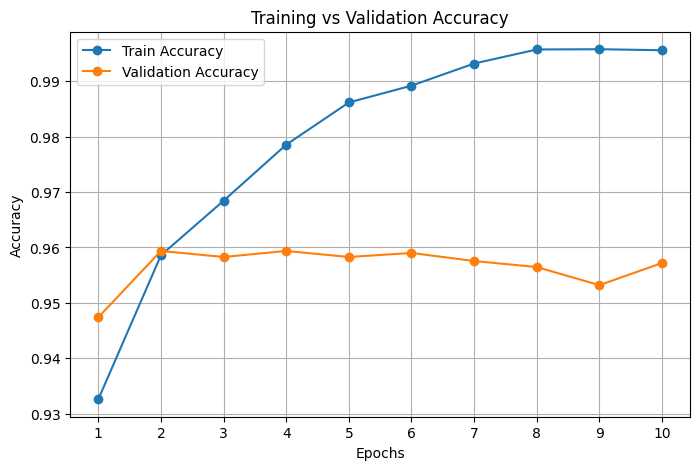

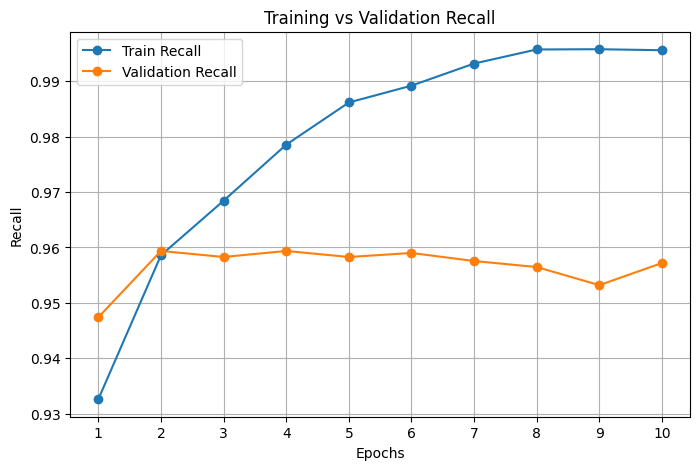

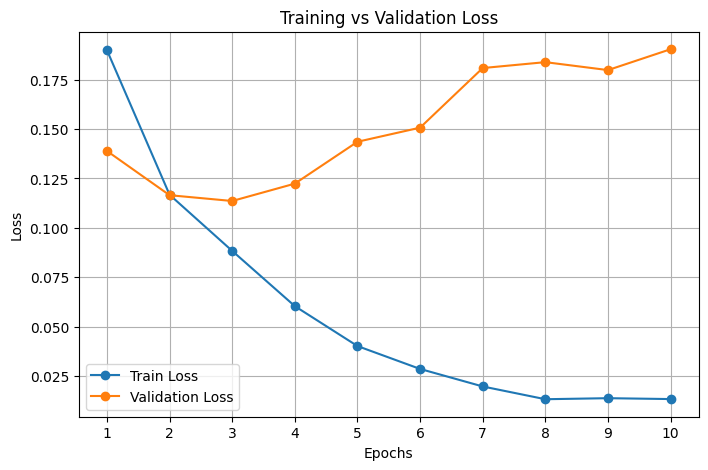

In [23]:
import matplotlib.pyplot as plt

epochs = range(1, len(history["train_acc"]) + 1)

# Accuracy
plt.figure(figsize=(8, 5))
plt.plot(epochs, history["train_acc"], marker="o", label="Train Accuracy")
plt.plot(epochs, history["val_acc"], marker="o", label="Validation Accuracy")
plt.title("Training vs Validation Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.xticks(list(epochs))
plt.legend()
plt.grid()
plt.show()

# Recall
plt.figure(figsize=(8, 5))
plt.plot(epochs, history["train_recall"], marker="o", label="Train Recall")
plt.plot(epochs, history["val_recall"], marker="o", label="Validation Recall")
plt.title("Training vs Validation Recall")
plt.xlabel("Epochs")
plt.ylabel("Recall")
plt.xticks(list(epochs))
plt.legend()
plt.grid()
plt.show()

# Loss
plt.figure(figsize=(8, 5))
plt.plot(epochs, history["train_loss"], marker="o", label="Train Loss")
plt.plot(epochs, history["val_loss"], marker="o", label="Validation Loss")
plt.title("Training vs Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.xticks(list(epochs))
plt.legend()
plt.grid()
plt.show()

In [ ]:
# early stoping

In [30]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import copy

EPOCHS = 10
PATIENCE = 3

best_val_acc = 0.0
patience_counter = 0

history = {
    "train_loss": [],
    "val_loss": [],
    "train_acc": [],
    "val_acc": [],
    "train_recall": [],
    "val_recall": [],
    "train_precision": [],
    "val_precision": [],
    "train_f1": [],
    "val_f1": []
}

best_model_weights = copy.deepcopy(model.state_dict())

for epoch in range(EPOCHS):

    # =========================
    # TRAINING
    # =========================
    model.train()

    running_loss = 0.0
    train_true = []
    train_pred = []

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * labels.size(0)

        predictions = outputs.argmax(dim=1)

        train_true.extend(labels.cpu().numpy())
        train_pred.extend(predictions.detach().cpu().numpy())

    train_loss = running_loss / len(train_loader.dataset)

    train_acc = accuracy_score(train_true, train_pred)
    train_precision = precision_score(
        train_true, train_pred, average="macro", zero_division=0
    )
    train_recall = recall_score(
        train_true, train_pred, average="macro", zero_division=0
    )
    train_f1 = f1_score(
        train_true, train_pred, average="macro", zero_division=0
    )

    # =========================
    # VALIDATION
    # =========================
    model.eval()

    val_true = []
    val_pred = []
    val_loss_total = 0.0

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            val_loss_total += loss.item() * labels.size(0)

            predictions = outputs.argmax(dim=1)

            val_true.extend(labels.cpu().numpy())
            val_pred.extend(predictions.cpu().numpy())

    val_loss = val_loss_total / len(val_loader.dataset)

    val_acc = accuracy_score(val_true, val_pred)
    val_precision = precision_score(
        val_true, val_pred, average="macro", zero_division=0
    )
    val_recall = recall_score(
        val_true, val_pred, average="macro", zero_division=0
    )
    val_f1 = f1_score(
        val_true, val_pred, average="macro", zero_division=0
    )

    # =========================
    # SAVE HISTORY
    # =========================
    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)

    history["train_acc"].append(train_acc)
    history["val_acc"].append(val_acc)

    history["train_recall"].append(train_recall)
    history["val_recall"].append(val_recall)

    history["train_precision"].append(train_precision)
    history["val_precision"].append(val_precision)

    history["train_f1"].append(train_f1)
    history["val_f1"].append(val_f1)

    # =========================
    # PRINT METRICS
    # =========================
    print(f"\nEpoch {epoch + 1}/{EPOCHS}")

    print(
        f"Train | Loss: {train_loss:.4f} | "
        f"Accuracy: {train_acc:.4f} | "
        f"Precision: {train_precision:.4f} | "
        f"Recall: {train_recall:.4f} | "
        f"F1: {train_f1:.4f}"
    )

    print(
        f"Val   | Loss: {val_loss:.4f} | "
        f"Accuracy: {val_acc:.4f} | "
        f"Precision: {val_precision:.4f} | "
        f"Recall: {val_recall:.4f} | "
        f"F1: {val_f1:.4f}"
    )

    # =========================
    # EARLY STOPPING ON ACCURACY
    # =========================
    if val_acc > best_val_acc:

        best_val_acc = val_acc
        patience_counter = 0

        best_model_weights = copy.deepcopy(model.state_dict())

        torch.save(
            best_model_weights,
            "best_hybrid_mobilenetv2.pth"
        )

        print("Validation accuracy improved! Model saved.")

    else:

        patience_counter += 1

        print(f"No improvement: {patience_counter}/{PATIENCE}")

        if patience_counter >= PATIENCE:
            print("\nEarly stopping triggered!")
            break


# =========================
# RESTORE BEST MODEL
# =========================
model.load_state_dict(best_model_weights)
model.eval()

print("\nBest model restored!")
print(f"Best validation accuracy: {best_val_acc * 100:.2f}%")
print(f"Epochs completed: {len(history['train_acc'])}")


Epoch 1/10
Train | Loss: 0.1971 | Accuracy: 0.9297 | Precision: 0.9299 | Recall: 0.9297 | F1: 0.9297
Val   | Loss: 0.1269 | Accuracy: 0.9546 | Precision: 0.9555 | Recall: 0.9546 | F1: 0.9546
Validation accuracy improved! Model saved.

Epoch 2/10
Train | Loss: 0.1130 | Accuracy: 0.9600 | Precision: 0.9602 | Recall: 0.9600 | F1: 0.9600
Val   | Loss: 0.1183 | Accuracy: 0.9561 | Precision: 0.9567 | Recall: 0.9561 | F1: 0.9561
Validation accuracy improved! Model saved.

Epoch 3/10
Train | Loss: 0.0885 | Accuracy: 0.9683 | Precision: 0.9685 | Recall: 0.9683 | F1: 0.9683
Val   | Loss: 0.1062 | Accuracy: 0.9615 | Precision: 0.9616 | Recall: 0.9615 | F1: 0.9615
Validation accuracy improved! Model saved.

Epoch 4/10
Train | Loss: 0.0644 | Accuracy: 0.9773 | Precision: 0.9774 | Recall: 0.9773 | F1: 0.9773
Val   | Loss: 0.1234 | Accuracy: 0.9608 | Precision: 0.9609 | Recall: 0.9608 | F1: 0.9608
No improvement: 1/3

Epoch 5/10
Train | Loss: 0.0386 | Accuracy: 0.9860 | Precision: 0.9860 | Recall: 0

In [32]:
torch.save(model.state_dict(), "hybrid_mobilenetv2_resnet_bottleneck_yearlystopping.pth")

In [35]:
import torch
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Load your best saved hybrid_mobilenetv2_resnet_bottleneck.pth model
model.load_state_dict(
    torch.load(
        "hybrid_mobilenetv2_resnet_bottleneck_yearlystopping.pth",
        map_location=device,
        weights_only=True
    )
)

model.to(device)
model.eval()

y_true = []
y_pred = []
test_loss = 0.0

criterion = torch.nn.CrossEntropyLoss()

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        loss = criterion(outputs, labels)

        test_loss += loss.item() * labels.size(0)

        predictions = outputs.argmax(dim=1)

        y_true.extend(labels.cpu().tolist())
        y_pred.extend(predictions.cpu().tolist())

# Average test loss
test_loss /= len(test_loader.dataset)

# Calculate metrics
accuracy = accuracy_score(y_true, y_pred)

precision = precision_score(
    y_true, y_pred, average="macro", zero_division=0
)

recall = recall_score(
    y_true, y_pred, average="macro", zero_division=0
)

f1 = f1_score(
    y_true, y_pred, average="macro", zero_division=0
)

print("\n========== FINAL TEST RESULTS ==========")
print(f"Test Loss:  {test_loss:.4f}")
print(f"Accuracy:   {accuracy:.4f} ({accuracy * 100:.2f}%)")
print(f"Precision:  {precision:.4f}")
print(f"Recall:     {recall:.4f}")
print(f"F1-score:   {f1:.4f}")

print("\n========== CLASSIFICATION REPORT ==========")
print(classification_report(
    y_true,
    y_pred,
    labels=list(range(len(class_names))),
    target_names=class_names,
    zero_division=0
))

print("\n========== CONFUSION MATRIX ==========")
print(confusion_matrix(
    y_true,
    y_pred,
    labels=list(range(len(class_names)))
))


========== FINAL TEST RESULTS ==========
Test Loss:  0.1820
Accuracy:   0.9604 (96.04%)
Precision:  0.9605
Recall:     0.9604
F1-score:   0.9604

========== CLASSIFICATION REPORT ==========
              precision    recall  f1-score   support

 Parasitized       0.96      0.96      0.96      1378
  Uninfected       0.96      0.96      0.96      1378

    accuracy                           0.96      2756
   macro avg       0.96      0.96      0.96      2756
weighted avg       0.96      0.96      0.96      2756


========== CONFUSION MATRIX ==========
[[1325   53]
 [  56 1322]]


In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

EPOCHS = 10

for epoch in range(EPOCHS):

    # =========================
    # Training
    # =========================
    model.train()

    running_loss = 0.0
    train_true = []
    train_pred = []

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * labels.size(0)

        predictions = outputs.argmax(dim=1)

        train_true.extend(labels.cpu().numpy())
        train_pred.extend(predictions.detach().cpu().numpy())

    train_loss = running_loss / len(train_loader.dataset)

    train_acc = accuracy_score(train_true, train_pred)
    train_precision = precision_score(
        train_true, train_pred, average="macro", zero_division=0
    )
    train_recall = recall_score(
        train_true, train_pred, average="macro", zero_division=0
    )
    train_f1 = f1_score(
        train_true, train_pred, average="macro", zero_division=0
    )

    # =========================
    # Validation
    # =========================
    model.eval()

    val_true = []
    val_pred = []
    val_loss_total = 0.0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            val_loss_total += loss.item() * labels.size(0)

            predictions = outputs.argmax(dim=1)

            val_true.extend(labels.cpu().numpy())
            val_pred.extend(predictions.cpu().numpy())

    val_loss = val_loss_total / len(val_loader.dataset)

    val_acc = accuracy_score(val_true, val_pred)
    val_precision = precision_score(
        val_true, val_pred, average="macro", zero_division=0
    )
    val_recall = recall_score(
        val_true, val_pred, average="macro", zero_division=0
    )
    val_f1 = f1_score(
        val_true, val_pred, average="macro", zero_division=0
    )

    # =========================
    # Print metrics
    # =========================
    print(f"\nEpoch {epoch + 1}/{EPOCHS}")
    print(
        f"Train | Loss: {train_loss:.4f} | "
        f"Accuracy: {train_acc:.4f} | "
        f"Precision: {train_precision:.4f} | "
        f"Recall: {train_recall:.4f} | "
        f"F1: {train_f1:.4f}"
    )

    print(
        f"Val   | Loss: {val_loss:.4f} | "
        f"Accuracy: {val_acc:.4f} | "
        f"Precision: {val_precision:.4f} | "
        f"Recall: {val_recall:.4f} | "
        f"F1: {val_f1:.4f}"
    )


Epoch 1/10
Train | Loss: 0.1956 | Accuracy: 0.9310 | Precision: 0.9311 | Recall: 0.9310 | F1: 0.9310
Val   | Loss: 0.1276 | Accuracy: 0.9536 | Precision: 0.9538 | Recall: 0.9536 | F1: 0.9536

Epoch 2/10
Train | Loss: 0.1145 | Accuracy: 0.9604 | Precision: 0.9605 | Recall: 0.9604 | F1: 0.9604
Val   | Loss: 0.1170 | Accuracy: 0.9539 | Precision: 0.9542 | Recall: 0.9539 | F1: 0.9539

Epoch 3/10
Train | Loss: 0.0862 | Accuracy: 0.9692 | Precision: 0.9693 | Recall: 0.9692 | F1: 0.9692
Val   | Loss: 0.1171 | Accuracy: 0.9565 | Precision: 0.9565 | Recall: 0.9565 | F1: 0.9565

Epoch 4/10
Train | Loss: 0.0635 | Accuracy: 0.9776 | Precision: 0.9776 | Recall: 0.9776 | F1: 0.9776
Val   | Loss: 0.1202 | Accuracy: 0.9579 | Precision: 0.9579 | Recall: 0.9579 | F1: 0.9579

Epoch 5/10
Train | Loss: 0.0353 | Accuracy: 0.9878 | Precision: 0.9878 | Recall: 0.9878 | F1: 0.9878
Val   | Loss: 0.1423 | Accuracy: 0.9546 | Precision: 0.9548 | Recall: 0.9546 | F1: 0.9546

Epoch 6/10
Train | Loss: 0.0260 | Accur

In [ ]:
total_params = sum(
    p.numel() for p in model.parameters()
)

print(f"Total parameters: {total_params:,}")

Total parameters: 6,046,466


In [ ]:
torch.save(model.state_dict(), "hybrid_mobilenetv2_resnet_bottleneck.pth")

In [ ]:
import torch
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Load your best saved hybrid_mobilenetv2_resnet_bottleneck.pth model
model.load_state_dict(
    torch.load(
        "hybrid_mobilenetv2_resnet_bottleneck.pth",
        map_location=device,
        weights_only=True
    )
)

model.to(device)
model.eval()

y_true = []
y_pred = []
test_loss = 0.0

criterion = torch.nn.CrossEntropyLoss()

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        loss = criterion(outputs, labels)

        test_loss += loss.item() * labels.size(0)

        predictions = outputs.argmax(dim=1)

        y_true.extend(labels.cpu().tolist())
        y_pred.extend(predictions.cpu().tolist())

# Average test loss
test_loss /= len(test_loader.dataset)

# Calculate metrics
accuracy = accuracy_score(y_true, y_pred)

precision = precision_score(
    y_true, y_pred, average="macro", zero_division=0
)

recall = recall_score(
    y_true, y_pred, average="macro", zero_division=0
)

f1 = f1_score(
    y_true, y_pred, average="macro", zero_division=0
)

print("\n========== FINAL TEST RESULTS ==========")
print(f"Test Loss:  {test_loss:.4f}")
print(f"Accuracy:   {accuracy:.4f} ({accuracy * 100:.2f}%)")
print(f"Precision:  {precision:.4f}")
print(f"Recall:     {recall:.4f}")
print(f"F1-score:   {f1:.4f}")

print("\n========== CLASSIFICATION REPORT ==========")
print(classification_report(
    y_true,
    y_pred,
    labels=list(range(len(class_names))),
    target_names=class_names,
    zero_division=0
))

print("\n========== CONFUSION MATRIX ==========")
print(confusion_matrix(
    y_true,
    y_pred,
    labels=list(range(len(class_names)))
))


========== FINAL TEST RESULTS ==========
Test Loss:  0.1895
Accuracy:   0.9615 (96.15%)
Precision:  0.9624
Recall:     0.9615
F1-score:   0.9615

========== CLASSIFICATION REPORT ==========
              precision    recall  f1-score   support

 Parasitized       0.98      0.94      0.96      1378
  Uninfected       0.94      0.98      0.96      1378

    accuracy                           0.96      2756
   macro avg       0.96      0.96      0.96      2756
weighted avg       0.96      0.96      0.96      2756


========== CONFUSION MATRIX ==========
[[1295   83]
 [  23 1355]]


In [43]:
class_names = dataset.classes
print("Classes:", class_names)

Classes: ['Parasitized', 'Uninfected']


In [44]:
# 4. Load pretrained MobileNetV2
# =========================
weights = models.MobileNet_V2_Weights.DEFAULT
model = models.mobilenet_v2(weights=weights)

# Freeze every feature-extractor layer
for param in model.features.parameters():
    param.requires_grad = False

# Unfreeze the last 3 feature blocks
for block in list(model.features.children())[-3:]:
    for param in block.parameters():
        param.requires_grad = True

# Replace the classifier for 2 classes
in_features = model.classifier[1].in_features

model.classifier[1] = nn.Linear(
    in_features, len(class_names)
)

model = model.to(device)

In [45]:
criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.AdamW([
    {
        "params": [
            p for p in model.features.parameters()
            if p.requires_grad
        ],
        "lr": 1e-5
    },
    {
        "params": model.classifier.parameters(),
        "lr": 1e-3
    }
], weight_decay=1e-4)

In [47]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

EPOCHS = 10

# Store metrics for every epoch
history = {
    "train_loss": [],
    "val_loss": [],
    "train_acc": [],
    "val_acc": [],
    "train_recall": [],
    "val_recall": [],
    "train_precision": [],
    "val_precision": [],
    "train_f1": [],
    "val_f1": []
}

for epoch in range(EPOCHS):

    # =========================
    # Training
    # =========================
    model.train()

    running_loss = 0.0
    train_true = []
    train_pred = []

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * labels.size(0)

        predictions = outputs.argmax(dim=1)

        train_true.extend(labels.cpu().numpy())
        train_pred.extend(predictions.detach().cpu().numpy())

    train_loss = running_loss / len(train_loader.dataset)

    train_acc = accuracy_score(train_true, train_pred)
    train_precision = precision_score(
        train_true, train_pred, average="macro", zero_division=0
    )
    train_recall = recall_score(
        train_true, train_pred, average="macro", zero_division=0
    )
    train_f1 = f1_score(
        train_true, train_pred, average="macro", zero_division=0
    )

    # =========================
    # Validation
    # =========================
    model.eval()

    val_true = []
    val_pred = []
    val_loss_total = 0.0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            val_loss_total += loss.item() * labels.size(0)

            predictions = outputs.argmax(dim=1)

            val_true.extend(labels.cpu().numpy())
            val_pred.extend(predictions.cpu().numpy())

    val_loss = val_loss_total / len(val_loader.dataset)

    val_acc = accuracy_score(val_true, val_pred)
    val_precision = precision_score(
        val_true, val_pred, average="macro", zero_division=0
    )
    val_recall = recall_score(
        val_true, val_pred, average="macro", zero_division=0
    )
    val_f1 = f1_score(
        val_true, val_pred, average="macro", zero_division=0
    )

    # =========================
    # SAVE METRICS IN HISTORY
    # =========================
    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)

    history["train_acc"].append(train_acc)
    history["val_acc"].append(val_acc)

    history["train_recall"].append(train_recall)
    history["val_recall"].append(val_recall)

    history["train_precision"].append(train_precision)
    history["val_precision"].append(val_precision)

    history["train_f1"].append(train_f1)
    history["val_f1"].append(val_f1)

    # =========================
    # Print metrics
    # =========================
    print(f"\nEpoch {epoch + 1}/{EPOCHS}")

    print(
        f"Train | Loss: {train_loss:.4f} | "
        f"Accuracy: {train_acc:.4f} | "
        f"Precision: {train_precision:.4f} | "
        f"Recall: {train_recall:.4f} | "
        f"F1: {train_f1:.4f}"
    )

    print(
        f"Val   | Loss: {val_loss:.4f} | "
        f"Accuracy: {val_acc:.4f} | "
        f"Precision: {val_precision:.4f} | "
        f"Recall: {val_recall:.4f} | "
        f"F1: {val_f1:.4f}"
    )


Epoch 1/10
Train | Loss: 0.2239 | Accuracy: 0.9187 | Precision: 0.9189 | Recall: 0.9187 | F1: 0.9187
Val   | Loss: 0.1680 | Accuracy: 0.9383 | Precision: 0.9387 | Recall: 0.9383 | F1: 0.9383

Epoch 2/10
Train | Loss: 0.1656 | Accuracy: 0.9413 | Precision: 0.9415 | Recall: 0.9413 | F1: 0.9413
Val   | Loss: 0.1525 | Accuracy: 0.9478 | Precision: 0.9478 | Recall: 0.9478 | F1: 0.9477

Epoch 3/10
Train | Loss: 0.1504 | Accuracy: 0.9456 | Precision: 0.9459 | Recall: 0.9456 | F1: 0.9456
Val   | Loss: 0.1466 | Accuracy: 0.9459 | Precision: 0.9464 | Recall: 0.9459 | F1: 0.9459

Epoch 4/10
Train | Loss: 0.1428 | Accuracy: 0.9492 | Precision: 0.9495 | Recall: 0.9492 | F1: 0.9492
Val   | Loss: 0.1410 | Accuracy: 0.9456 | Precision: 0.9463 | Recall: 0.9456 | F1: 0.9456

Epoch 5/10
Train | Loss: 0.1273 | Accuracy: 0.9556 | Precision: 0.9558 | Recall: 0.9556 | F1: 0.9556
Val   | Loss: 0.1412 | Accuracy: 0.9514 | Precision: 0.9514 | Recall: 0.9514 | F1: 0.9514

Epoch 6/10
Train | Loss: 0.1207 | Accur

In [49]:
torch.save(model.state_dict(), "new_mobilenetv2_resnet.pth")

In [51]:
import torch
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Load your best saved hybrid_mobilenetv2_resnet.pth model
model.load_state_dict(
    torch.load(
        "new_mobilenetv2_resnet.pth",
        map_location=device,
        weights_only=True
    )
)

model.to(device)
model.eval()

y_true = []
y_pred = []
test_loss = 0.0

criterion = torch.nn.CrossEntropyLoss()

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        loss = criterion(outputs, labels)

        test_loss += loss.item() * labels.size(0)

        predictions = outputs.argmax(dim=1)

        y_true.extend(labels.cpu().tolist())
        y_pred.extend(predictions.cpu().tolist())

# Average test loss
test_loss /= len(test_loader.dataset)

# Calculate metrics
accuracy = accuracy_score(y_true, y_pred)

precision = precision_score(
    y_true, y_pred, average="macro", zero_division=0
)

recall = recall_score(
    y_true, y_pred, average="macro", zero_division=0
)

f1 = f1_score(
    y_true, y_pred, average="macro", zero_division=0
)

print("\n========== FINAL TEST RESULTS ==========")
print(f"Test Loss:  {test_loss:.4f}")
print(f"Accuracy:   {accuracy:.4f} ({accuracy * 100:.2f}%)")
print(f"Precision:  {precision:.4f}")
print(f"Recall:     {recall:.4f}")
print(f"F1-score:   {f1:.4f}")

print("\n========== CLASSIFICATION REPORT ==========")
print(classification_report(
    y_true,
    y_pred,
    labels=list(range(len(class_names))),
    target_names=class_names,
    zero_division=0
))

print("\n========== CONFUSION MATRIX ==========")
print(confusion_matrix(
    y_true,
    y_pred,
    labels=list(range(len(class_names)))
))


========== FINAL TEST RESULTS ==========
Test Loss:  0.1917
Accuracy:   0.9282 (92.82%)
Precision:  0.9318
Recall:     0.9282
F1-score:   0.9280

========== CLASSIFICATION REPORT ==========
              precision    recall  f1-score   support

 Parasitized       0.89      0.97      0.93      1378
  Uninfected       0.97      0.88      0.92      1378

    accuracy                           0.93      2756
   macro avg       0.93      0.93      0.93      2756
weighted avg       0.93      0.93      0.93      2756


========== CONFUSION MATRIX ==========
[[1342   36]
 [ 162 1216]]


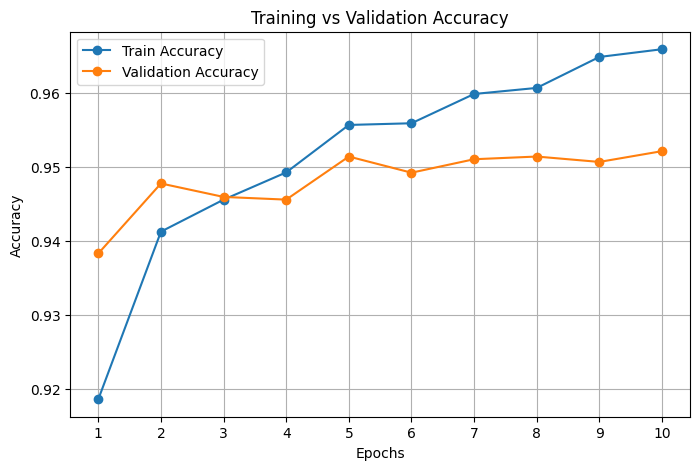

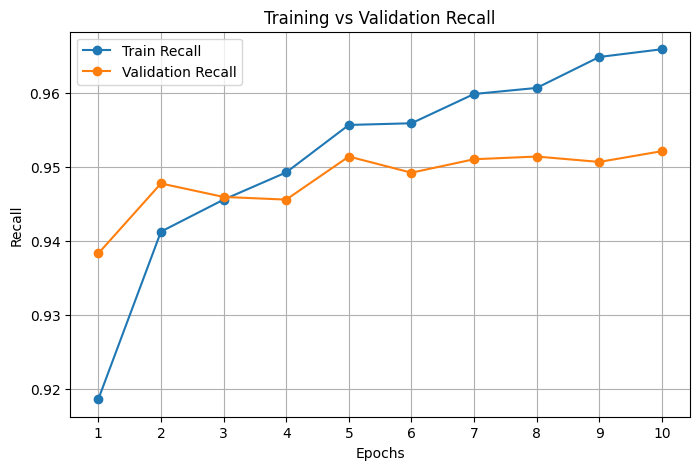

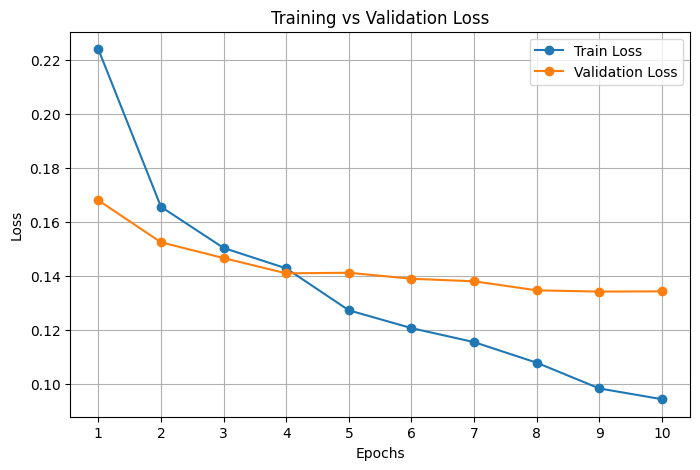

In [52]:
import matplotlib.pyplot as plt

epochs = range(1, len(history["train_acc"]) + 1)

# Accuracy
plt.figure(figsize=(8, 5))
plt.plot(epochs, history["train_acc"], marker="o", label="Train Accuracy")
plt.plot(epochs, history["val_acc"], marker="o", label="Validation Accuracy")
plt.title("Training vs Validation Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.xticks(list(epochs))
plt.legend()
plt.grid()
plt.show()

# Recall
plt.figure(figsize=(8, 5))
plt.plot(epochs, history["train_recall"], marker="o", label="Train Recall")
plt.plot(epochs, history["val_recall"], marker="o", label="Validation Recall")
plt.title("Training vs Validation Recall")
plt.xlabel("Epochs")
plt.ylabel("Recall")
plt.xticks(list(epochs))
plt.legend()
plt.grid()
plt.show()

# Loss
plt.figure(figsize=(8, 5))
plt.plot(epochs, history["train_loss"], marker="o", label="Train Loss")
plt.plot(epochs, history["val_loss"], marker="o", label="Validation Loss")
plt.title("Training vs Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.xticks(list(epochs))
plt.legend()
plt.grid()
plt.show()

In [46]:
EPOCHS = 10
best_val_acc = 0.0

for epoch in range(EPOCHS):

    # Training
    model.train()

    running_loss = 0.0
    train_true, train_pred = [], []

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * labels.size(0)

        predictions = outputs.argmax(dim=1)
        train_true.extend(labels.detach().cpu().tolist())
        train_pred.extend(predictions.detach().cpu().tolist())

    train_loss = running_loss / len(train_loader.dataset)

    train_acc = accuracy_score(train_true, train_pred)
    train_precision = precision_score(
        train_true, train_pred, average="macro", zero_division=0
    )
    train_recall = recall_score(
        train_true, train_pred, average="macro", zero_division=0
    )
    train_f1 = f1_score(
        train_true, train_pred, average="macro", zero_division=0
    )

    # Validation
    model.eval()

    val_true, val_pred = [], []
    val_loss_total = 0.0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            val_loss_total += loss.item() * labels.size(0)

            predictions = outputs.argmax(dim=1)
            val_true.extend(labels.cpu().tolist())
            val_pred.extend(predictions.cpu().tolist())

    val_loss = val_loss_total / len(val_loader.dataset)

    val_acc = accuracy_score(val_true, val_pred)
    val_precision = precision_score(
        val_true, val_pred, average="macro", zero_division=0
    )
    val_recall = recall_score(
        val_true, val_pred, average="macro", zero_division=0
    )
    val_f1 = f1_score(
        val_true, val_pred, average="macro", zero_division=0
    )

    print(f"\nEpoch {epoch + 1}/{EPOCHS}")
    print(
        f"Train Loss: {train_loss:.4f} | "
        f"Acc: {train_acc:.4f} | "
        f"Precision: {train_precision:.4f} | "
        f"Recall: {train_recall:.4f} | "
        f"F1: {train_f1:.4f}"
    )
    print(
        f"Val Loss: {val_loss:.4f} | "
        f"Acc: {val_acc:.4f} | "
        f"Precision: {val_precision:.4f} | "
        f"Recall: {val_recall:.4f} | "
        f"F1: {val_f1:.4f}"
    )

    # Save best model using validation accuracy
    if val_acc > best_val_acc:
        best_val_acc = val_acc

        torch.save(
            model.state_dict(),
            "best_mobilenetv2.pth"
        )

        print("Best model saved!")

KeyboardInterrupt: 

In [ ]:
import torch
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Load your best saved MobileNetV2 model
model.load_state_dict(
    torch.load(
        "best_mobilenetv2.pth",
        map_location=device,
        weights_only=True
    )
)

model.to(device)
model.eval()

y_true = []
y_pred = []
test_loss = 0.0

criterion = torch.nn.CrossEntropyLoss()

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        loss = criterion(outputs, labels)

        test_loss += loss.item() * labels.size(0)

        predictions = outputs.argmax(dim=1)

        y_true.extend(labels.cpu().tolist())
        y_pred.extend(predictions.cpu().tolist())

# Average test loss
test_loss /= len(test_loader.dataset)

# Calculate metrics
accuracy = accuracy_score(y_true, y_pred)

precision = precision_score(
    y_true, y_pred, average="macro", zero_division=0
)

recall = recall_score(
    y_true, y_pred, average="macro", zero_division=0
)

f1 = f1_score(
    y_true, y_pred, average="macro", zero_division=0
)

print("\n========== FINAL TEST RESULTS ==========")
print(f"Test Loss:  {test_loss:.4f}")
print(f"Accuracy:   {accuracy:.4f} ({accuracy * 100:.2f}%)")
print(f"Precision:  {precision:.4f}")
print(f"Recall:     {recall:.4f}")
print(f"F1-score:   {f1:.4f}")

print("\n========== CLASSIFICATION REPORT ==========")
print(classification_report(
    y_true,
    y_pred,
    labels=list(range(len(class_names))),
    target_names=class_names,
    zero_division=0
))

print("\n========== CONFUSION MATRIX ==========")
print(confusion_matrix(
    y_true,
    y_pred,
    labels=list(range(len(class_names)))
))


========== FINAL TEST RESULTS ==========
Test Loss:  0.1197
Accuracy:   0.9550 (95.50%)
Precision:  0.9551
Recall:     0.9550
F1-score:   0.9550

========== CLASSIFICATION REPORT ==========
              precision    recall  f1-score   support

 Parasitized       0.96      0.95      0.95      1378
  Uninfected       0.95      0.96      0.96      1378

    accuracy                           0.96      2756
   macro avg       0.96      0.96      0.96      2756
weighted avg       0.96      0.96      0.96      2756


========== CONFUSION MATRIX ==========
[[1306   72]
 [  52 1326]]


In [ ]:
import torch
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Load your best saved hybrid_mobilenetv2_resnet.pth model
model.load_state_dict(
    torch.load(
        "hybrid_mobilenetv2_resnet.pth",
        map_location=device,
        weights_only=True
    )
)

model.to(device)
model.eval()

y_true = []
y_pred = []
test_loss = 0.0

criterion = torch.nn.CrossEntropyLoss()

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        loss = criterion(outputs, labels)

        test_loss += loss.item() * labels.size(0)

        predictions = outputs.argmax(dim=1)

        y_true.extend(labels.cpu().tolist())
        y_pred.extend(predictions.cpu().tolist())

# Average test loss
test_loss /= len(test_loader.dataset)

# Calculate metrics
accuracy = accuracy_score(y_true, y_pred)

precision = precision_score(
    y_true, y_pred, average="macro", zero_division=0
)

recall = recall_score(
    y_true, y_pred, average="macro", zero_division=0
)

f1 = f1_score(
    y_true, y_pred, average="macro", zero_division=0
)

print("\n========== FINAL TEST RESULTS ==========")
print(f"Test Loss:  {test_loss:.4f}")
print(f"Accuracy:   {accuracy:.4f} ({accuracy * 100:.2f}%)")
print(f"Precision:  {precision:.4f}")
print(f"Recall:     {recall:.4f}")
print(f"F1-score:   {f1:.4f}")

print("\n========== CLASSIFICATION REPORT ==========")
print(classification_report(
    y_true,
    y_pred,
    labels=list(range(len(class_names))),
    target_names=class_names,
    zero_division=0
))

print("\n========== CONFUSION MATRIX ==========")
print(confusion_matrix(
    y_true,
    y_pred,
    labels=list(range(len(class_names)))
))

RuntimeError: Error(s) in loading state_dict for HybridMobileNetV2:
	Missing key(s) in state_dict: "refinement.0.block.0.weight", "refinement.0.block.1.weight", "refinement.0.block.1.bias", "refinement.0.block.1.running_mean", "refinement.0.block.1.running_var", "refinement.0.block.3.weight", "refinement.0.block.4.weight", "refinement.0.block.4.bias", "refinement.0.block.4.running_mean", "refinement.0.block.4.running_var", "refinement.0.block.6.weight", "refinement.0.block.7.weight", "refinement.0.block.7.bias", "refinement.0.block.7.running_mean", "refinement.0.block.7.running_var", "refinement.1.block.0.weight", "refinement.1.block.1.weight", "refinement.1.block.1.bias", "refinement.1.block.1.running_mean", "refinement.1.block.1.running_var", "refinement.1.block.3.weight", "refinement.1.block.4.weight", "refinement.1.block.4.bias", "refinement.1.block.4.running_mean", "refinement.1.block.4.running_var", "refinement.1.block.6.weight", "refinement.1.block.7.weight", "refinement.1.block

In [ ]:
import torch

model = HybridMobileNetV2(num_classes=2)

model.load_state_dict(
    torch.load("hybrid_mobilenetv2_resnet.pth", map_location="cuda", weights_only=True)
)

model.eval()
print("Trained model loaded successfully!")

RuntimeError: Error(s) in loading state_dict for HybridMobileNetV2:
	Missing key(s) in state_dict: "refinement.0.block.0.weight", "refinement.0.block.1.weight", "refinement.0.block.1.bias", "refinement.0.block.1.running_mean", "refinement.0.block.1.running_var", "refinement.0.block.3.weight", "refinement.0.block.4.weight", "refinement.0.block.4.bias", "refinement.0.block.4.running_mean", "refinement.0.block.4.running_var", "refinement.0.block.6.weight", "refinement.0.block.7.weight", "refinement.0.block.7.bias", "refinement.0.block.7.running_mean", "refinement.0.block.7.running_var", "refinement.1.block.0.weight", "refinement.1.block.1.weight", "refinement.1.block.1.bias", "refinement.1.block.1.running_mean", "refinement.1.block.1.running_var", "refinement.1.block.3.weight", "refinement.1.block.4.weight", "refinement.1.block.4.bias", "refinement.1.block.4.running_mean", "refinement.1.block.4.running_var", "refinement.1.block.6.weight", "refinement.1.block.7.weight", "refinement.1.block

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import models, datasets, transforms
from torch.utils.data import DataLoader, Subset
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score
)

# 1. Device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)


# 2. EXACT model architecture you used previously
class HybridMobileNetV2(nn.Module):
    def __init__(self, num_classes=2):
        super().__init__()

        # weights=None avoids downloading pretrained weights.
        # The checkpoint supplies the trained weights.
        base = models.mobilenet_v2(weights=None)

        self.backbone = base.features
        channels = base.last_channel

        self.refinement = nn.Sequential(
            nn.Conv2d(channels, 256, 1, bias=False),
            nn.BatchNorm2d(256),
            nn.ReLU6(inplace=True),

            nn.Conv2d(
                256, 256, 3,
                padding=1, groups=256, bias=False
            ),
            nn.BatchNorm2d(256),
            nn.ReLU6(inplace=True),

            nn.Conv2d(256, channels, 1, bias=False),
            nn.BatchNorm2d(channels)
        )

        # Initialization is unnecessary when loading the checkpoint.
        self.pool = nn.AdaptiveAvgPool2d(1)

        self.classifier = nn.Sequential(
            nn.Dropout(0.2),
            nn.Linear(channels, num_classes)
        )

    def forward(self, x):
        x = self.backbone(x)
        x = F.relu6(x + self.refinement(x))
        x = self.pool(x)
        x = torch.flatten(x, 1)
        return self.classifier(x)


# 3. Load checkpoint
model = HybridMobileNetV2(num_classes=2).to(device)

checkpoint = torch.load(
    "/content/hybrid_mobilenetv2_resnet.pth",
    map_location=device,
    weights_only=True
)

# Support a raw state_dict or a wrapped checkpoint
if "model_state_dict" in checkpoint:
    checkpoint = checkpoint["model_state_dict"]
elif "state_dict" in checkpoint:
    checkpoint = checkpoint["state_dict"]

model.load_state_dict(checkpoint, strict=True)
model.eval()

print("Trained model loaded successfully!")




# 6. Evaluate without training
y_true = []
y_pred = []
test_loss = 0.0

criterion = torch.nn.CrossEntropyLoss()

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        loss = criterion(outputs, labels)

        test_loss += loss.item() * labels.size(0)

        predictions = outputs.argmax(dim=1)

        y_true.extend(labels.cpu().tolist())
        y_pred.extend(predictions.cpu().tolist())

# Average test loss
test_loss /= len(test_loader.dataset)

# Calculate metrics
accuracy = accuracy_score(y_true, y_pred)

precision = precision_score(
    y_true, y_pred, average="macro", zero_division=0
)

recall = recall_score(
    y_true, y_pred, average="macro", zero_division=0
)

f1 = f1_score(
    y_true, y_pred, average="macro", zero_division=0
)

print("\n========== FINAL TEST RESULTS ==========")
print(f"Test Loss:  {test_loss:.4f}")
print(f"Accuracy:   {accuracy:.4f} ({accuracy * 100:.2f}%)")
print(f"Precision:  {precision:.4f}")
print(f"Recall:     {recall:.4f}")
print(f"F1-score:   {f1:.4f}")

print("\n========== CLASSIFICATION REPORT ==========")
print(classification_report(
    y_true,
    y_pred,
    labels=list(range(len(class_names))),
    target_names=class_names,
    zero_division=0
))

print("\n========== CONFUSION MATRIX ==========")
print(confusion_matrix(
    y_true,
    y_pred,
    labels=list(range(len(class_names)))
))

Device: cuda
Trained model loaded successfully!

========== FINAL TEST RESULTS ==========
Test Loss:  0.1809
Accuracy:   0.9630 (96.30%)
Precision:  0.9630
Recall:     0.9630
F1-score:   0.9630

========== CLASSIFICATION REPORT ==========
              precision    recall  f1-score   support

 Parasitized       0.96      0.96      0.96      1378
  Uninfected       0.96      0.96      0.96      1378

    accuracy                           0.96      2756
   macro avg       0.96      0.96      0.96      2756
weighted avg       0.96      0.96      0.96      2756


========== CONFUSION MATRIX ==========
[[1328   50]
 [  52 1326]]


In [ ]:
total_params = sum(
    p.numel() for p in model.parameters()
)

print(f"Total parameters: {total_params:,}")

In [53]:
import torch
import torch.nn as nn
from torchvision import models
import torch.nn.functional as F

class HybridMobileNetV2(nn.Module):
    def __init__(self, num_classes=2):
        super().__init__()

        # Load pretrained MobileNetV2
        base = models.mobilenet_v2(
            weights=models.MobileNet_V2_Weights.DEFAULT
        )

        self.backbone = base.features
        channels = base.last_channel  # 1280

        # Hybrid residual refinement block
        self.refinement = nn.Sequential(
            nn.Conv2d(channels, 256, 1, bias=False),
            nn.BatchNorm2d(256),
            nn.ReLU6(inplace=True),

            nn.Conv2d(
                256, 256, 3,
                padding=1, groups=256, bias=False
            ),
            nn.BatchNorm2d(256),
            nn.ReLU6(inplace=True),

            nn.Conv2d(256, channels, 1, bias=False),
            nn.BatchNorm2d(channels)
        )

        # Initially preserve the pretrained features
        nn.init.zeros_(self.refinement[-1].weight)
        nn.init.zeros_(self.refinement[-1].bias)

        self.pool = nn.AdaptiveAvgPool2d(1)
        self.classifier = nn.Sequential(
            nn.Dropout(0.2),
            nn.Linear(channels, num_classes)
        )

    def forward(self, x):
        x = self.backbone(x)
        x = F.relu6(x + self.refinement(x))
        x = self.pool(x)
        x = torch.flatten(x, 1)
        return self.classifier(x)

In [54]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model = HybridMobileNetV2(num_classes=2).to(device)

print("Device:", device)
print("Model created successfully!")

Device: cuda
Model created successfully!


In [38]:
criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.AdamW([
    {
        "params": model.backbone.parameters(),
        "lr": 1e-5
    },
    {
        "params": list(model.refinement.parameters())
                  + list(model.classifier.parameters()),
        "lr": 1e-3
    }
], weight_decay=1e-4)

In [39]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

EPOCHS = 10

# Store metrics for every epoch
history = {
    "train_loss": [],
    "val_loss": [],
    "train_acc": [],
    "val_acc": [],
    "train_recall": [],
    "val_recall": [],
    "train_precision": [],
    "val_precision": [],
    "train_f1": [],
    "val_f1": []
}

for epoch in range(EPOCHS):

    # =========================
    # Training
    # =========================
    model.train()

    running_loss = 0.0
    train_true = []
    train_pred = []

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * labels.size(0)

        predictions = outputs.argmax(dim=1)

        train_true.extend(labels.cpu().numpy())
        train_pred.extend(predictions.detach().cpu().numpy())

    train_loss = running_loss / len(train_loader.dataset)

    train_acc = accuracy_score(train_true, train_pred)
    train_precision = precision_score(
        train_true, train_pred, average="macro", zero_division=0
    )
    train_recall = recall_score(
        train_true, train_pred, average="macro", zero_division=0
    )
    train_f1 = f1_score(
        train_true, train_pred, average="macro", zero_division=0
    )

    # =========================
    # Validation
    # =========================
    model.eval()

    val_true = []
    val_pred = []
    val_loss_total = 0.0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            val_loss_total += loss.item() * labels.size(0)

            predictions = outputs.argmax(dim=1)

            val_true.extend(labels.cpu().numpy())
            val_pred.extend(predictions.cpu().numpy())

    val_loss = val_loss_total / len(val_loader.dataset)

    val_acc = accuracy_score(val_true, val_pred)
    val_precision = precision_score(
        val_true, val_pred, average="macro", zero_division=0
    )
    val_recall = recall_score(
        val_true, val_pred, average="macro", zero_division=0
    )
    val_f1 = f1_score(
        val_true, val_pred, average="macro", zero_division=0
    )

    # =========================
    # SAVE METRICS IN HISTORY
    # =========================
    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)

    history["train_acc"].append(train_acc)
    history["val_acc"].append(val_acc)

    history["train_recall"].append(train_recall)
    history["val_recall"].append(val_recall)

    history["train_precision"].append(train_precision)
    history["val_precision"].append(val_precision)

    history["train_f1"].append(train_f1)
    history["val_f1"].append(val_f1)

    # =========================
    # Print metrics
    # =========================
    print(f"\nEpoch {epoch + 1}/{EPOCHS}")

    print(
        f"Train | Loss: {train_loss:.4f} | "
        f"Accuracy: {train_acc:.4f} | "
        f"Precision: {train_precision:.4f} | "
        f"Recall: {train_recall:.4f} | "
        f"F1: {train_f1:.4f}"
    )

    print(
        f"Val   | Loss: {val_loss:.4f} | "
        f"Accuracy: {val_acc:.4f} | "
        f"Precision: {val_precision:.4f} | "
        f"Recall: {val_recall:.4f} | "
        f"F1: {val_f1:.4f}"
    )



Epoch 1/10
Train | Loss: 0.1888 | Accuracy: 0.9286 | Precision: 0.9287 | Recall: 0.9286 | F1: 0.9286
Val   | Loss: 0.1309 | Accuracy: 0.9528 | Precision: 0.9531 | Recall: 0.9528 | F1: 0.9528

Epoch 2/10
Train | Loss: 0.1139 | Accuracy: 0.9595 | Precision: 0.9597 | Recall: 0.9595 | F1: 0.9595
Val   | Loss: 0.1179 | Accuracy: 0.9579 | Precision: 0.9583 | Recall: 0.9579 | F1: 0.9579

Epoch 3/10
Train | Loss: 0.0875 | Accuracy: 0.9682 | Precision: 0.9684 | Recall: 0.9682 | F1: 0.9682
Val   | Loss: 0.1249 | Accuracy: 0.9546 | Precision: 0.9551 | Recall: 0.9546 | F1: 0.9546

Epoch 4/10
Train | Loss: 0.0633 | Accuracy: 0.9772 | Precision: 0.9772 | Recall: 0.9772 | F1: 0.9772
Val   | Loss: 0.1290 | Accuracy: 0.9539 | Precision: 0.9539 | Recall: 0.9539 | F1: 0.9539

Epoch 5/10
Train | Loss: 0.0425 | Accuracy: 0.9848 | Precision: 0.9848 | Recall: 0.9848 | F1: 0.9848
Val   | Loss: 0.1626 | Accuracy: 0.9528 | Precision: 0.9541 | Recall: 0.9528 | F1: 0.9528

Epoch 6/10
Train | Loss: 0.0284 | Accur

In [40]:
import torch
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Load your best saved hybrid_mobilenetv2_resnet.pth model
model.load_state_dict(
    torch.load(
        "hybrid_mobilenetv2_resnet.pth",
        map_location=device,
        weights_only=True
    )
)

model.to(device)
model.eval()

y_true = []
y_pred = []
test_loss = 0.0

criterion = torch.nn.CrossEntropyLoss()

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        loss = criterion(outputs, labels)

        test_loss += loss.item() * labels.size(0)

        predictions = outputs.argmax(dim=1)

        y_true.extend(labels.cpu().tolist())
        y_pred.extend(predictions.cpu().tolist())

# Average test loss
test_loss /= len(test_loader.dataset)

# Calculate metrics
accuracy = accuracy_score(y_true, y_pred)

precision = precision_score(
    y_true, y_pred, average="macro", zero_division=0
)

recall = recall_score(
    y_true, y_pred, average="macro", zero_division=0
)

f1 = f1_score(
    y_true, y_pred, average="macro", zero_division=0
)

print("\n========== FINAL TEST RESULTS ==========")
print(f"Test Loss:  {test_loss:.4f}")
print(f"Accuracy:   {accuracy:.4f} ({accuracy * 100:.2f}%)")
print(f"Precision:  {precision:.4f}")
print(f"Recall:     {recall:.4f}")
print(f"F1-score:   {f1:.4f}")

print("\n========== CLASSIFICATION REPORT ==========")
print(classification_report(
    y_true,
    y_pred,
    labels=list(range(len(class_names))),
    target_names=class_names,
    zero_division=0
))

print("\n========== CONFUSION MATRIX ==========")
print(confusion_matrix(
    y_true,
    y_pred,
    labels=list(range(len(class_names)))
))

In [41]:
import torch
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Load your best saved hybrid_mobilenetv2_resnet.pth model
model.load_state_dict(
    torch.load(
        "hybrid_mobilenetv2_resnet.pth",
        map_location=device,
        weights_only=True
    )
)

model.to(device)
model.eval()

y_true = []
y_pred = []
test_loss = 0.0

criterion = torch.nn.CrossEntropyLoss()

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        loss = criterion(outputs, labels)

        test_loss += loss.item() * labels.size(0)

        predictions = outputs.argmax(dim=1)

        y_true.extend(labels.cpu().tolist())
        y_pred.extend(predictions.cpu().tolist())

# Average test loss
test_loss /= len(test_loader.dataset)

# Calculate metrics
accuracy = accuracy_score(y_true, y_pred)

precision = precision_score(
    y_true, y_pred, average="macro", zero_division=0
)

recall = recall_score(
    y_true, y_pred, average="macro", zero_division=0
)

f1 = f1_score(
    y_true, y_pred, average="macro", zero_division=0
)

print("\n========== FINAL TEST RESULTS ==========")
print(f"Test Loss:  {test_loss:.4f}")
print(f"Accuracy:   {accuracy:.4f} ({accuracy * 100:.2f}%)")
print(f"Precision:  {precision:.4f}")
print(f"Recall:     {recall:.4f}")
print(f"F1-score:   {f1:.4f}")

print("\n========== CLASSIFICATION REPORT ==========")
print(classification_report(
    y_true,
    y_pred,
    labels=list(range(len(class_names))),
    target_names=class_names,
    zero_division=0
))

print("\n========== CONFUSION MATRIX ==========")
print(confusion_matrix(
    y_true,
    y_pred,
    labels=list(range(len(class_names)))
))


========== FINAL TEST RESULTS ==========
Test Loss:  0.1987
Accuracy:   0.9641 (96.41%)
Precision:  0.9642
Recall:     0.9641
F1-score:   0.9641

========== CLASSIFICATION REPORT ==========
              precision    recall  f1-score   support

 Parasitized       0.97      0.96      0.96      1378
  Uninfected       0.96      0.97      0.96      1378

    accuracy                           0.96      2756
   macro avg       0.96      0.96      0.96      2756
weighted avg       0.96      0.96      0.96      2756


========== CONFUSION MATRIX ==========
[[1319   59]
 [  40 1338]]


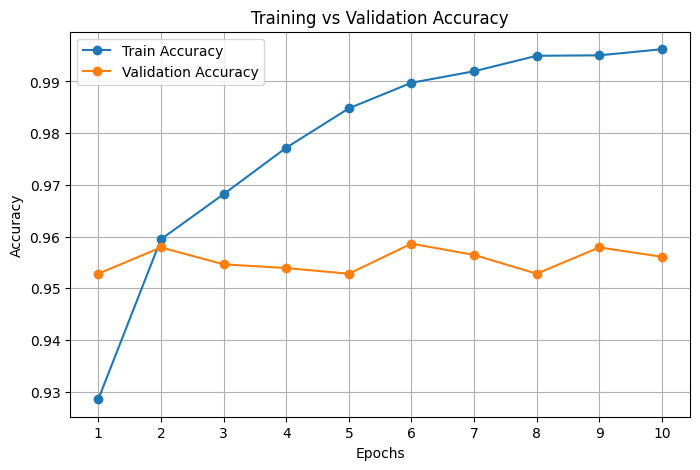

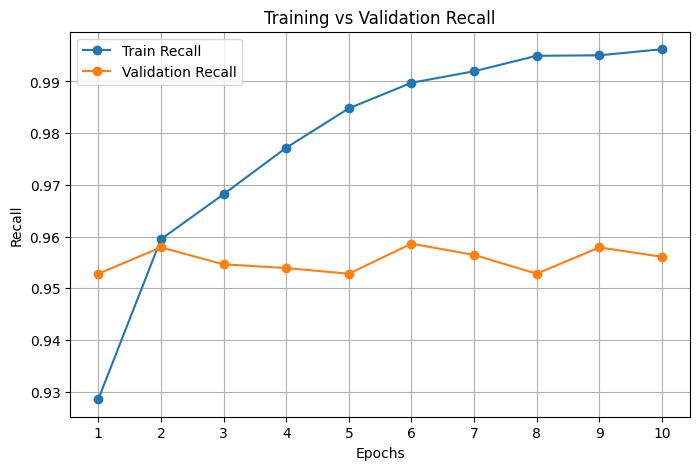

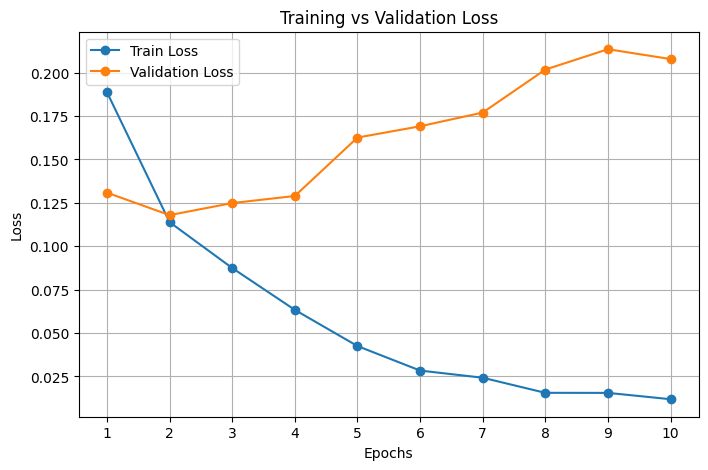

In [42]:
import matplotlib.pyplot as plt

epochs = range(1, len(history["train_acc"]) + 1)

# Accuracy
plt.figure(figsize=(8, 5))
plt.plot(epochs, history["train_acc"], marker="o", label="Train Accuracy")
plt.plot(epochs, history["val_acc"], marker="o", label="Validation Accuracy")
plt.title("Training vs Validation Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.xticks(list(epochs))
plt.legend()
plt.grid()
plt.show()

# Recall
plt.figure(figsize=(8, 5))
plt.plot(epochs, history["train_recall"], marker="o", label="Train Recall")
plt.plot(epochs, history["val_recall"], marker="o", label="Validation Recall")
plt.title("Training vs Validation Recall")
plt.xlabel("Epochs")
plt.ylabel("Recall")
plt.xticks(list(epochs))
plt.legend()
plt.grid()
plt.show()

# Loss
plt.figure(figsize=(8, 5))
plt.plot(epochs, history["train_loss"], marker="o", label="Train Loss")
plt.plot(epochs, history["val_loss"], marker="o", label="Validation Loss")
plt.title("Training vs Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.xticks(list(epochs))
plt.legend()
plt.grid()
plt.show()

In [ ]:
#hybrid with freezing layer

In [ ]:
for param in model.features.parameters():
    param.requires_grad = False

# Unfreeze the last 3 feature blocks
for block in list(model.features.children())[-3:]:
    for param in block.parameters():
        param.requires_grad = True

In [55]:
import torch
import torch.nn as nn
from torchvision import models
import torch.nn.functional as F

class HybridMobileNetV2(nn.Module):
    def __init__(self, num_classes=2):
        super().__init__()

        # Load pretrained MobileNetV2
        base = models.mobilenet_v2(
            weights=models.MobileNet_V2_Weights.DEFAULT
        )

        self.backbone = base.features
        channels = base.last_channel  # 1280

        # Freeze all MobileNetV2 layers
        for param in self.backbone.parameters():
            param.requires_grad = False

        # Unfreeze only the last 3 feature modules
        for layer in self.backbone[-3:]:
            for param in layer.parameters():
                param.requires_grad = True

        # Hybrid residual refinement block
        self.refinement = nn.Sequential(
            nn.Conv2d(channels, 256, 1, bias=False),
            nn.BatchNorm2d(256),
            nn.ReLU6(inplace=True),

            nn.Conv2d(
                256, 256, 3,
                padding=1, groups=256, bias=False
            ),
            nn.BatchNorm2d(256),
            nn.ReLU6(inplace=True),

            nn.Conv2d(256, channels, 1, bias=False),
            nn.BatchNorm2d(channels)
        )

        # Initially preserve pretrained features
        nn.init.zeros_(self.refinement[-1].weight)
        nn.init.zeros_(self.refinement[-1].bias)

        self.pool = nn.AdaptiveAvgPool2d(1)

        self.classifier = nn.Sequential(
            nn.Dropout(0.2),
            nn.Linear(channels, num_classes)
        )

    def forward(self, x):
        x = self.backbone(x)
        x = F.relu6(x + self.refinement(x))
        x = self.pool(x)
        x = torch.flatten(x, 1)
        return self.classifier(x)

In [56]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model = HybridMobileNetV2(num_classes=2).to(device)

print("Device:", device)
print("Model created successfully!")

Device: cuda
Model created successfully!


In [57]:
criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.AdamW([
    {
        "params": model.backbone.parameters(),
        "lr": 1e-5
    },
    {
        "params": list(model.refinement.parameters())
                  + list(model.classifier.parameters()),
        "lr": 1e-3
    }
], weight_decay=1e-4)

In [58]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

EPOCHS = 10

# Store metrics for every epoch
history = {
    "train_loss": [],
    "val_loss": [],
    "train_acc": [],
    "val_acc": [],
    "train_recall": [],
    "val_recall": [],
    "train_precision": [],
    "val_precision": [],
    "train_f1": [],
    "val_f1": []
}

for epoch in range(EPOCHS):

    # =========================
    # Training
    # =========================
    model.train()

    running_loss = 0.0
    train_true = []
    train_pred = []

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * labels.size(0)

        predictions = outputs.argmax(dim=1)

        train_true.extend(labels.cpu().numpy())
        train_pred.extend(predictions.detach().cpu().numpy())

    train_loss = running_loss / len(train_loader.dataset)

    train_acc = accuracy_score(train_true, train_pred)
    train_precision = precision_score(
        train_true, train_pred, average="macro", zero_division=0
    )
    train_recall = recall_score(
        train_true, train_pred, average="macro", zero_division=0
    )
    train_f1 = f1_score(
        train_true, train_pred, average="macro", zero_division=0
    )

    # =========================
    # Validation
    # =========================
    model.eval()

    val_true = []
    val_pred = []
    val_loss_total = 0.0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            val_loss_total += loss.item() * labels.size(0)

            predictions = outputs.argmax(dim=1)

            val_true.extend(labels.cpu().numpy())
            val_pred.extend(predictions.cpu().numpy())

    val_loss = val_loss_total / len(val_loader.dataset)

    val_acc = accuracy_score(val_true, val_pred)
    val_precision = precision_score(
        val_true, val_pred, average="macro", zero_division=0
    )
    val_recall = recall_score(
        val_true, val_pred, average="macro", zero_division=0
    )
    val_f1 = f1_score(
        val_true, val_pred, average="macro", zero_division=0
    )

    # =========================
    # SAVE METRICS IN HISTORY
    # =========================
    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)

    history["train_acc"].append(train_acc)
    history["val_acc"].append(val_acc)

    history["train_recall"].append(train_recall)
    history["val_recall"].append(val_recall)

    history["train_precision"].append(train_precision)
    history["val_precision"].append(val_precision)

    history["train_f1"].append(train_f1)
    history["val_f1"].append(val_f1)

    # =========================
    # Print metrics
    # =========================
    print(f"\nEpoch {epoch + 1}/{EPOCHS}")

    print(
        f"Train | Loss: {train_loss:.4f} | "
        f"Accuracy: {train_acc:.4f} | "
        f"Precision: {train_precision:.4f} | "
        f"Recall: {train_recall:.4f} | "
        f"F1: {train_f1:.4f}"
    )

    print(
        f"Val   | Loss: {val_loss:.4f} | "
        f"Accuracy: {val_acc:.4f} | "
        f"Precision: {val_precision:.4f} | "
        f"Recall: {val_recall:.4f} | "
        f"F1: {val_f1:.4f}"
    )


Epoch 1/10
Train | Loss: 0.2130 | Accuracy: 0.9222 | Precision: 0.9224 | Recall: 0.9222 | F1: 0.9222
Val   | Loss: 0.1556 | Accuracy: 0.9445 | Precision: 0.9446 | Recall: 0.9445 | F1: 0.9445

Epoch 2/10
Train | Loss: 0.1465 | Accuracy: 0.9487 | Precision: 0.9491 | Recall: 0.9487 | F1: 0.9487
Val   | Loss: 0.1532 | Accuracy: 0.9390 | Precision: 0.9397 | Recall: 0.9390 | F1: 0.9390

Epoch 3/10
Train | Loss: 0.1171 | Accuracy: 0.9587 | Precision: 0.9589 | Recall: 0.9587 | F1: 0.9587
Val   | Loss: 0.1489 | Accuracy: 0.9427 | Precision: 0.9441 | Recall: 0.9427 | F1: 0.9426

Epoch 4/10
Train | Loss: 0.0895 | Accuracy: 0.9669 | Precision: 0.9670 | Recall: 0.9669 | F1: 0.9669
Val   | Loss: 0.1513 | Accuracy: 0.9441 | Precision: 0.9450 | Recall: 0.9441 | F1: 0.9441

Epoch 5/10
Train | Loss: 0.0697 | Accuracy: 0.9750 | Precision: 0.9750 | Recall: 0.9750 | F1: 0.9750
Val   | Loss: 0.1684 | Accuracy: 0.9521 | Precision: 0.9521 | Recall: 0.9521 | F1: 0.9521

Epoch 6/10
Train | Loss: 0.0532 | Accur

In [60]:
torch.save(model.state_dict(), "mobilenetv2_resnet_freeeze.pth")

In [61]:
import torch
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Load your best saved hybrid_mobilenetv2_resnet.pth model
model.load_state_dict(
    torch.load(
        "mobilenetv2_resnet_freeeze.pth",
        map_location=device,
        weights_only=True
    )
)

model.to(device)
model.eval()

y_true = []
y_pred = []
test_loss = 0.0

criterion = torch.nn.CrossEntropyLoss()

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        loss = criterion(outputs, labels)

        test_loss += loss.item() * labels.size(0)

        predictions = outputs.argmax(dim=1)

        y_true.extend(labels.cpu().tolist())
        y_pred.extend(predictions.cpu().tolist())

# Average test loss
test_loss /= len(test_loader.dataset)

# Calculate metrics
accuracy = accuracy_score(y_true, y_pred)

precision = precision_score(
    y_true, y_pred, average="macro", zero_division=0
)

recall = recall_score(
    y_true, y_pred, average="macro", zero_division=0
)

f1 = f1_score(
    y_true, y_pred, average="macro", zero_division=0
)

print("\n========== FINAL TEST RESULTS ==========")
print(f"Test Loss:  {test_loss:.4f}")
print(f"Accuracy:   {accuracy:.4f} ({accuracy * 100:.2f}%)")
print(f"Precision:  {precision:.4f}")
print(f"Recall:     {recall:.4f}")
print(f"F1-score:   {f1:.4f}")

print("\n========== CLASSIFICATION REPORT ==========")
print(classification_report(
    y_true,
    y_pred,
    labels=list(range(len(class_names))),
    target_names=class_names,
    zero_division=0
))

print("\n========== CONFUSION MATRIX ==========")
print(confusion_matrix(
    y_true,
    y_pred,
    labels=list(range(len(class_names)))
))


========== FINAL TEST RESULTS ==========
Test Loss:  0.1987
Accuracy:   0.9641 (96.41%)
Precision:  0.9642
Recall:     0.9641
F1-score:   0.9641

========== CLASSIFICATION REPORT ==========
              precision    recall  f1-score   support

 Parasitized       0.97      0.96      0.96      1378
  Uninfected       0.96      0.97      0.96      1378

    accuracy                           0.96      2756
   macro avg       0.96      0.96      0.96      2756
weighted avg       0.96      0.96      0.96      2756


========== CONFUSION MATRIX ==========
[[1319   59]
 [  40 1338]]


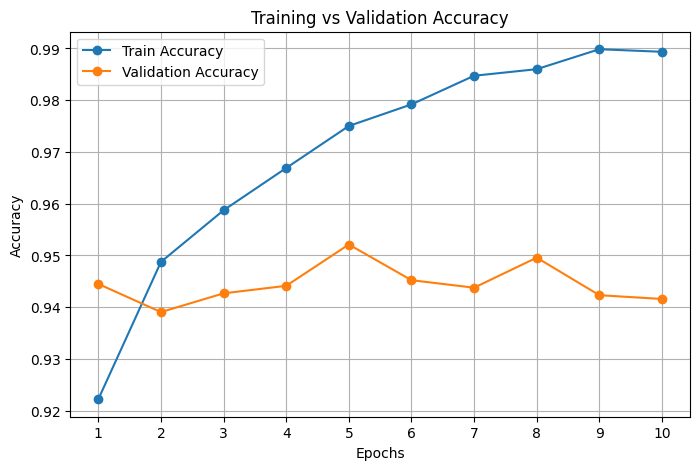

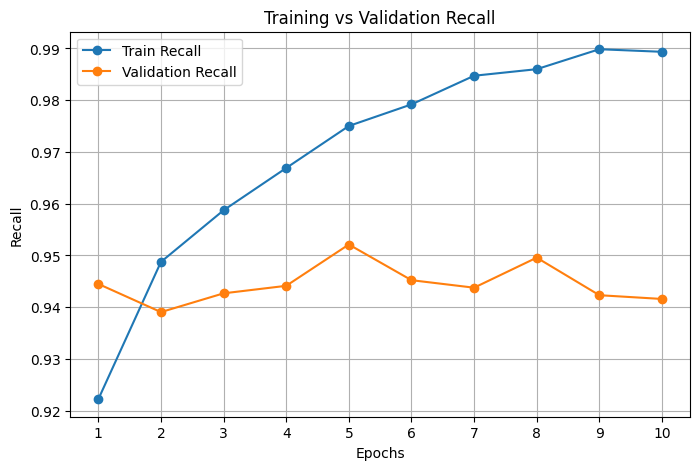

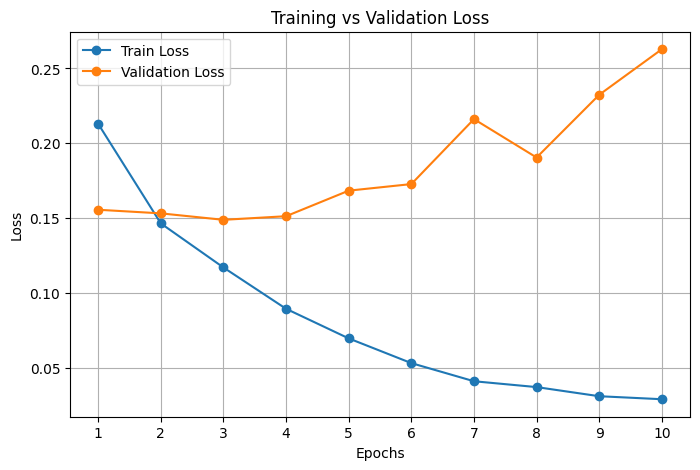

In [63]:
import matplotlib.pyplot as plt

epochs = range(1, len(history["train_acc"]) + 1)

# Accuracy
plt.figure(figsize=(8, 5))
plt.plot(epochs, history["train_acc"], marker="o", label="Train Accuracy")
plt.plot(epochs, history["val_acc"], marker="o", label="Validation Accuracy")
plt.title("Training vs Validation Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.xticks(list(epochs))
plt.legend()
plt.grid()
plt.show()

# Recall
plt.figure(figsize=(8, 5))
plt.plot(epochs, history["train_recall"], marker="o", label="Train Recall")
plt.plot(epochs, history["val_recall"], marker="o", label="Validation Recall")
plt.title("Training vs Validation Recall")
plt.xlabel("Epochs")
plt.ylabel("Recall")
plt.xticks(list(epochs))
plt.legend()
plt.grid()
plt.show()

# Loss
plt.figure(figsize=(8, 5))
plt.plot(epochs, history["train_loss"], marker="o", label="Train Loss")
plt.plot(epochs, history["val_loss"], marker="o", label="Validation Loss")
plt.title("Training vs Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.xticks(list(epochs))
plt.legend()
plt.grid()
plt.show()

In [ ]:
#mobilener+bottlenexk+freeze

In [64]:
class HybridMobileNetV2(nn.Module):
    def __init__(self, num_classes=2):
        super().__init__()

        base = models.mobilenet_v2(
            weights=models.MobileNet_V2_Weights.DEFAULT
        )

        self.backbone = base.features
        channels = base.last_channel  # 1280

        # Freeze entire MobileNetV2 backbone
        for param in self.backbone.parameters():
            param.requires_grad = False

        # Unfreeze last 3 feature blocks
        for block in list(self.backbone.children())[-3:]:
            for param in block.parameters():
                param.requires_grad = True

        # Four residual bottleneck blocks
        self.refinement = nn.Sequential(
            BottleneckResidual(channels, 256, depthwise=False),
            BottleneckResidual(channels, 256, depthwise=True),
            BottleneckResidual(channels, 256, depthwise=False),
            BottleneckResidual(channels, 256, depthwise=True)
        )

        self.pool = nn.AdaptiveAvgPool2d(1)

        self.classifier = nn.Sequential(
            nn.Dropout(0.2),
            nn.Linear(channels, num_classes)
        )

    def forward(self, x):
        x = self.backbone(x)
        x = self.refinement(x)
        x = self.pool(x)
        x = torch.flatten(x, 1)
        return self.classifier(x)

In [65]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model = HybridMobileNetV2(num_classes=2).to(device)

print("Device:", device)
print("Model created successfully!")

Device: cuda
Model created successfully!


In [66]:
criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.AdamW([
    {
        "params": model.backbone.parameters(),
        "lr": 1e-5
    },
    {
        "params": list(model.refinement.parameters())
                  + list(model.classifier.parameters()),
        "lr": 1e-3
    }
], weight_decay=1e-4)

In [67]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

EPOCHS = 10

# Store metrics for every epoch
history = {
    "train_loss": [],
    "val_loss": [],
    "train_acc": [],
    "val_acc": [],
    "train_recall": [],
    "val_recall": [],
    "train_precision": [],
    "val_precision": [],
    "train_f1": [],
    "val_f1": []
}

for epoch in range(EPOCHS):

    # =========================
    # Training
    # =========================
    model.train()

    running_loss = 0.0
    train_true = []
    train_pred = []

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * labels.size(0)

        predictions = outputs.argmax(dim=1)

        train_true.extend(labels.cpu().numpy())
        train_pred.extend(predictions.detach().cpu().numpy())

    train_loss = running_loss / len(train_loader.dataset)

    train_acc = accuracy_score(train_true, train_pred)
    train_precision = precision_score(
        train_true, train_pred, average="macro", zero_division=0
    )
    train_recall = recall_score(
        train_true, train_pred, average="macro", zero_division=0
    )
    train_f1 = f1_score(
        train_true, train_pred, average="macro", zero_division=0
    )

    # =========================
    # Validation
    # =========================
    model.eval()

    val_true = []
    val_pred = []
    val_loss_total = 0.0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            val_loss_total += loss.item() * labels.size(0)

            predictions = outputs.argmax(dim=1)

            val_true.extend(labels.cpu().numpy())
            val_pred.extend(predictions.cpu().numpy())

    val_loss = val_loss_total / len(val_loader.dataset)

    val_acc = accuracy_score(val_true, val_pred)
    val_precision = precision_score(
        val_true, val_pred, average="macro", zero_division=0
    )
    val_recall = recall_score(
        val_true, val_pred, average="macro", zero_division=0
    )
    val_f1 = f1_score(
        val_true, val_pred, average="macro", zero_division=0
    )

    # =========================
    # SAVE METRICS IN HISTORY
    # =========================
    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)

    history["train_acc"].append(train_acc)
    history["val_acc"].append(val_acc)

    history["train_recall"].append(train_recall)
    history["val_recall"].append(val_recall)

    history["train_precision"].append(train_precision)
    history["val_precision"].append(val_precision)

    history["train_f1"].append(train_f1)
    history["val_f1"].append(val_f1)

    # =========================
    # Print metrics
    # =========================
    print(f"\nEpoch {epoch + 1}/{EPOCHS}")

    print(
        f"Train | Loss: {train_loss:.4f} | "
        f"Accuracy: {train_acc:.4f} | "
        f"Precision: {train_precision:.4f} | "
        f"Recall: {train_recall:.4f} | "
        f"F1: {train_f1:.4f}"
    )

    print(
        f"Val   | Loss: {val_loss:.4f} | "
        f"Accuracy: {val_acc:.4f} | "
        f"Precision: {val_precision:.4f} | "
        f"Recall: {val_recall:.4f} | "
        f"F1: {val_f1:.4f}"
    )


Epoch 1/10
Train | Loss: 0.2033 | Accuracy: 0.9252 | Precision: 0.9256 | Recall: 0.9252 | F1: 0.9252
Val   | Loss: 0.1480 | Accuracy: 0.9456 | Precision: 0.9457 | Recall: 0.9456 | F1: 0.9456

Epoch 2/10
Train | Loss: 0.1423 | Accuracy: 0.9510 | Precision: 0.9512 | Recall: 0.9510 | F1: 0.9510
Val   | Loss: 0.1445 | Accuracy: 0.9528 | Precision: 0.9528 | Recall: 0.9528 | F1: 0.9528

Epoch 3/10
Train | Loss: 0.1154 | Accuracy: 0.9583 | Precision: 0.9584 | Recall: 0.9583 | F1: 0.9583
Val   | Loss: 0.1672 | Accuracy: 0.9452 | Precision: 0.9460 | Recall: 0.9452 | F1: 0.9452

Epoch 4/10
Train | Loss: 0.0907 | Accuracy: 0.9673 | Precision: 0.9673 | Recall: 0.9673 | F1: 0.9672
Val   | Loss: 0.1613 | Accuracy: 0.9470 | Precision: 0.9475 | Recall: 0.9470 | F1: 0.9470

Epoch 5/10
Train | Loss: 0.0653 | Accuracy: 0.9755 | Precision: 0.9755 | Recall: 0.9755 | F1: 0.9755
Val   | Loss: 0.1890 | Accuracy: 0.9488 | Precision: 0.9488 | Recall: 0.9488 | F1: 0.9488

Epoch 6/10
Train | Loss: 0.0475 | Accur

In [68]:
torch.save(model.state_dict(), "hybrid_mobilenetv2_resnet_bottlenec_freeeze.pth")

In [69]:
import torch
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Load your best saved hybrid_mobilenetv2_resnet.pth model
model.load_state_dict(
    torch.load(
        "hybrid_mobilenetv2_resnet_bottlenec_freeeze.pth",
        map_location=device,
        weights_only=True
    )
)

model.to(device)
model.eval()

y_true = []
y_pred = []
test_loss = 0.0

criterion = torch.nn.CrossEntropyLoss()

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        loss = criterion(outputs, labels)

        test_loss += loss.item() * labels.size(0)

        predictions = outputs.argmax(dim=1)

        y_true.extend(labels.cpu().tolist())
        y_pred.extend(predictions.cpu().tolist())

# Average test loss
test_loss /= len(test_loader.dataset)

# Calculate metrics
accuracy = accuracy_score(y_true, y_pred)

precision = precision_score(
    y_true, y_pred, average="macro", zero_division=0
)

recall = recall_score(
    y_true, y_pred, average="macro", zero_division=0
)

f1 = f1_score(
    y_true, y_pred, average="macro", zero_division=0
)

print("\n========== FINAL TEST RESULTS ==========")
print(f"Test Loss:  {test_loss:.4f}")
print(f"Accuracy:   {accuracy:.4f} ({accuracy * 100:.2f}%)")
print(f"Precision:  {precision:.4f}")
print(f"Recall:     {recall:.4f}")
print(f"F1-score:   {f1:.4f}")

print("\n========== CLASSIFICATION REPORT ==========")
print(classification_report(
    y_true,
    y_pred,
    labels=list(range(len(class_names))),
    target_names=class_names,
    zero_division=0
))

print("\n========== CONFUSION MATRIX ==========")
print(confusion_matrix(
    y_true,
    y_pred,
    labels=list(range(len(class_names)))
))


========== FINAL TEST RESULTS ==========
Test Loss:  0.2000
Accuracy:   0.9470 (94.70%)
Precision:  0.9479
Recall:     0.9470
F1-score:   0.9470

========== CLASSIFICATION REPORT ==========
              precision    recall  f1-score   support

 Parasitized       0.97      0.93      0.95      1378
  Uninfected       0.93      0.97      0.95      1378

    accuracy                           0.95      2756
   macro avg       0.95      0.95      0.95      2756
weighted avg       0.95      0.95      0.95      2756


========== CONFUSION MATRIX ==========
[[1275  103]
 [  43 1335]]


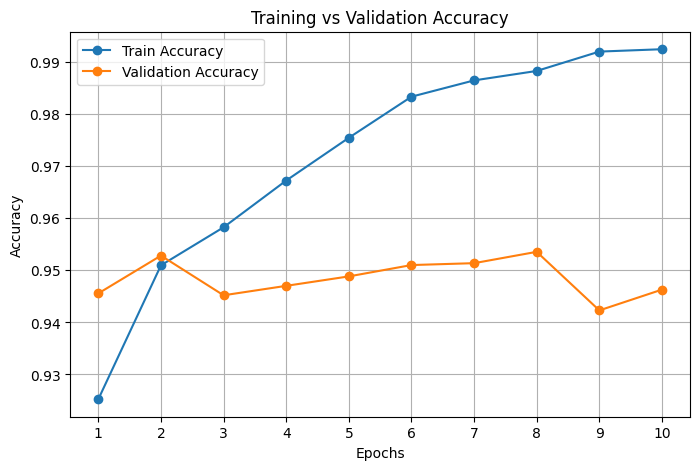

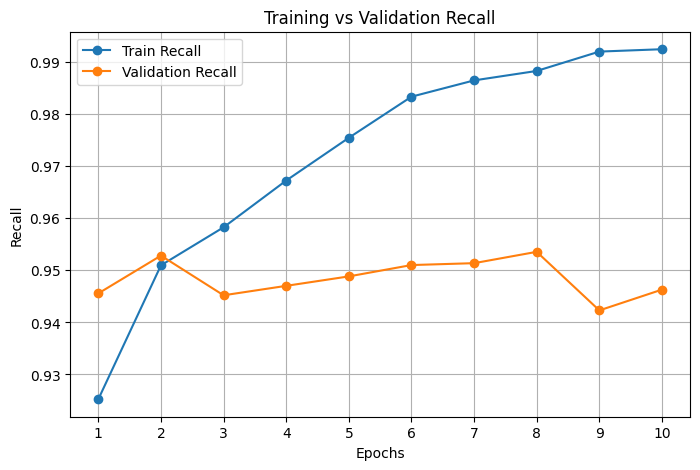

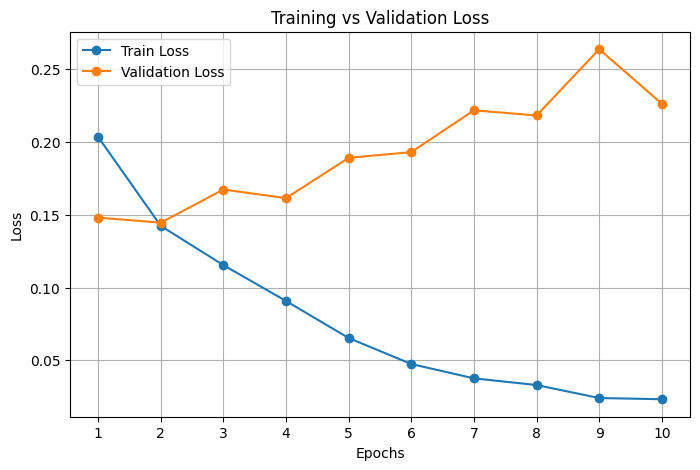

In [70]:
import matplotlib.pyplot as plt

epochs = range(1, len(history["train_acc"]) + 1)

# Accuracy
plt.figure(figsize=(8, 5))
plt.plot(epochs, history["train_acc"], marker="o", label="Train Accuracy")
plt.plot(epochs, history["val_acc"], marker="o", label="Validation Accuracy")
plt.title("Training vs Validation Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.xticks(list(epochs))
plt.legend()
plt.grid()
plt.show()

# Recall
plt.figure(figsize=(8, 5))
plt.plot(epochs, history["train_recall"], marker="o", label="Train Recall")
plt.plot(epochs, history["val_recall"], marker="o", label="Validation Recall")
plt.title("Training vs Validation Recall")
plt.xlabel("Epochs")
plt.ylabel("Recall")
plt.xticks(list(epochs))
plt.legend()
plt.grid()
plt.show()

# Loss
plt.figure(figsize=(8, 5))
plt.plot(epochs, history["train_loss"], marker="o", label="Train Loss")
plt.plot(epochs, history["val_loss"], marker="o", label="Validation Loss")
plt.title("Training vs Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.xticks(list(epochs))
plt.legend()
plt.grid()
plt.show()

In [ ]:
#more_freeze

In [99]:
import torch
import torch.nn as nn
from torchvision import models
import torch.nn.functional as F

class HybridMobileNetV2(nn.Module):
    def __init__(self, num_classes=2):
        super().__init__()

        # Load pretrained MobileNetV2
        base = models.mobilenet_v2(
            weights=models.MobileNet_V2_Weights.DEFAULT
        )

        self.backbone = base.features
        channels = base.last_channel  # 1280

        # Freeze all MobileNetV2 layers
        for param in self.backbone.parameters():
            param.requires_grad = False

        # Unfreeze only the last 3 feature modules
        for layer in self.backbone[-3:]:
            for param in layer.parameters():
                param.requires_grad = True

        # Hybrid residual refinement block
        self.refinement = nn.Sequential(
            nn.Conv2d(channels, 256, 1, bias=False),
            nn.BatchNorm2d(256),
            nn.ReLU6(inplace=True),
            nn.Dropout(0.5),

            nn.Conv2d(
                256, 256, 3,
                padding=1, groups=256, bias=False
            ),
            nn.BatchNorm2d(256),
            nn.ReLU6(inplace=True),
            nn.Dropout(0.5),

            nn.Conv2d(256, channels, 1, bias=False),
            nn.BatchNorm2d(channels)
        )

        # Initially preserve pretrained features
        nn.init.zeros_(self.refinement[-1].weight)
        nn.init.zeros_(self.refinement[-1].bias)

        self.pool = nn.AdaptiveAvgPool2d(1)

        self.classifier = nn.Sequential(
            nn.Dropout(0.2),
            nn.Linear(channels, num_classes)
        )

    def forward(self, x):
        x = self.backbone(x)
        x = F.relu6(x + self.refinement(x))
        x = self.pool(x)
        x = torch.flatten(x, 1)
        return self.classifier(x)

In [100]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model = HybridMobileNetV2(num_classes=2).to(device)

print("Device:", device)
print("Model created successfully!")

Device: cuda
Model created successfully!


In [101]:
criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.AdamW([
    {
        "params": model.backbone.parameters(),
        "lr": 1e-5
    },
    {
        "params": list(model.refinement.parameters())
                  + list(model.classifier.parameters()),
        "lr": 1e-3
    }
], weight_decay=1e-4)

In [102]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

EPOCHS = 10

# Store metrics for every epoch
history = {
    "train_loss": [],
    "val_loss": [],
    "train_acc": [],
    "val_acc": [],
    "train_recall": [],
    "val_recall": [],
    "train_precision": [],
    "val_precision": [],
    "train_f1": [],
    "val_f1": []
}

for epoch in range(EPOCHS):

    # =========================
    # Training
    # =========================
    model.train()

    running_loss = 0.0
    train_true = []
    train_pred = []

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * labels.size(0)

        predictions = outputs.argmax(dim=1)

        train_true.extend(labels.cpu().numpy())
        train_pred.extend(predictions.detach().cpu().numpy())

    train_loss = running_loss / len(train_loader.dataset)

    train_acc = accuracy_score(train_true, train_pred)
    train_precision = precision_score(
        train_true, train_pred, average="macro", zero_division=0
    )
    train_recall = recall_score(
        train_true, train_pred, average="macro", zero_division=0
    )
    train_f1 = f1_score(
        train_true, train_pred, average="macro", zero_division=0
    )

    # =========================
    # Validation
    # =========================
    model.eval()

    val_true = []
    val_pred = []
    val_loss_total = 0.0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            val_loss_total += loss.item() * labels.size(0)

            predictions = outputs.argmax(dim=1)

            val_true.extend(labels.cpu().numpy())
            val_pred.extend(predictions.cpu().numpy())

    val_loss = val_loss_total / len(val_loader.dataset)

    val_acc = accuracy_score(val_true, val_pred)
    val_precision = precision_score(
        val_true, val_pred, average="macro", zero_division=0
    )
    val_recall = recall_score(
        val_true, val_pred, average="macro", zero_division=0
    )
    val_f1 = f1_score(
        val_true, val_pred, average="macro", zero_division=0
    )

    # =========================
    # SAVE METRICS IN HISTORY
    # =========================
    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)

    history["train_acc"].append(train_acc)
    history["val_acc"].append(val_acc)

    history["train_recall"].append(train_recall)
    history["val_recall"].append(val_recall)

    history["train_precision"].append(train_precision)
    history["val_precision"].append(val_precision)

    history["train_f1"].append(train_f1)
    history["val_f1"].append(val_f1)

    # =========================
    # Print metrics
    # =========================
    print(f"\nEpoch {epoch + 1}/{EPOCHS}")

    print(
        f"Train | Loss: {train_loss:.4f} | "
        f"Accuracy: {train_acc:.4f} | "
        f"Precision: {train_precision:.4f} | "
        f"Recall: {train_recall:.4f} | "
        f"F1: {train_f1:.4f}"
    )

    print(
        f"Val   | Loss: {val_loss:.4f} | "
        f"Accuracy: {val_acc:.4f} | "
        f"Precision: {val_precision:.4f} | "
        f"Recall: {val_recall:.4f} | "
        f"F1: {val_f1:.4f}"
    )


Epoch 1/10
Train | Loss: 0.2210 | Accuracy: 0.9193 | Precision: 0.9196 | Recall: 0.9193 | F1: 0.9192
Val   | Loss: 0.1794 | Accuracy: 0.9234 | Precision: 0.9271 | Recall: 0.9234 | F1: 0.9233

Epoch 2/10
Train | Loss: 0.1550 | Accuracy: 0.9462 | Precision: 0.9465 | Recall: 0.9462 | F1: 0.9461
Val   | Loss: 0.1585 | Accuracy: 0.9369 | Precision: 0.9387 | Recall: 0.9369 | F1: 0.9368

Epoch 3/10
Train | Loss: 0.1392 | Accuracy: 0.9528 | Precision: 0.9531 | Recall: 0.9528 | F1: 0.9528
Val   | Loss: 0.1540 | Accuracy: 0.9409 | Precision: 0.9425 | Recall: 0.9409 | F1: 0.9408

Epoch 4/10
Train | Loss: 0.1227 | Accuracy: 0.9573 | Precision: 0.9574 | Recall: 0.9573 | F1: 0.9573
Val   | Loss: 0.1522 | Accuracy: 0.9419 | Precision: 0.9427 | Recall: 0.9419 | F1: 0.9419

Epoch 5/10
Train | Loss: 0.1042 | Accuracy: 0.9615 | Precision: 0.9617 | Recall: 0.9615 | F1: 0.9615
Val   | Loss: 0.1587 | Accuracy: 0.9343 | Precision: 0.9358 | Recall: 0.9343 | F1: 0.9343

Epoch 6/10
Train | Loss: 0.0963 | Accur

In [103]:
torch.save(model.state_dict(), "check.pth")

In [104]:
import torch
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Load your best saved hybrid_mobilenetv2_resnet.pth model
model.load_state_dict(
    torch.load(
        "check.pth",
        map_location=device,
        weights_only=True
    )
)

model.to(device)
model.eval()

y_true = []
y_pred = []
test_loss = 0.0

criterion = torch.nn.CrossEntropyLoss()

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        loss = criterion(outputs, labels)

        test_loss += loss.item() * labels.size(0)

        predictions = outputs.argmax(dim=1)

        y_true.extend(labels.cpu().tolist())
        y_pred.extend(predictions.cpu().tolist())

# Average test loss
test_loss /= len(test_loader.dataset)

# Calculate metrics
accuracy = accuracy_score(y_true, y_pred)

precision = precision_score(
    y_true, y_pred, average="macro", zero_division=0
)

recall = recall_score(
    y_true, y_pred, average="macro", zero_division=0
)

f1 = f1_score(
    y_true, y_pred, average="macro", zero_division=0
)

print("\n========== FINAL TEST RESULTS ==========")
print(f"Test Loss:  {test_loss:.4f}")
print(f"Accuracy:   {accuracy:.4f} ({accuracy * 100:.2f}%)")
print(f"Precision:  {precision:.4f}")
print(f"Recall:     {recall:.4f}")
print(f"F1-score:   {f1:.4f}")

print("\n========== CLASSIFICATION REPORT ==========")
print(classification_report(
    y_true,
    y_pred,
    labels=list(range(len(class_names))),
    target_names=class_names,
    zero_division=0
))

print("\n========== CONFUSION MATRIX ==========")
print(confusion_matrix(
    y_true,
    y_pred,
    labels=list(range(len(class_names)))
))


========== FINAL TEST RESULTS ==========
Test Loss:  0.1437
Accuracy:   0.9503 (95.03%)
Precision:  0.9507
Recall:     0.9503
F1-score:   0.9503

========== CLASSIFICATION REPORT ==========
              precision    recall  f1-score   support

 Parasitized       0.96      0.93      0.95      1378
  Uninfected       0.94      0.97      0.95      1378

    accuracy                           0.95      2756
   macro avg       0.95      0.95      0.95      2756
weighted avg       0.95      0.95      0.95      2756


========== CONFUSION MATRIX ==========
[[1288   90]
 [  47 1331]]
